
# 07 — Scenario Design and Feasible Catalog

## Objective

Design a diverse, feasible, and user-driven attack scenario catalog for MUBSIR using the validated findings and approved outputs from Notebooks 00–06.

The catalog will represent variation across four key dimensions:

1. **Attack Duration:** 5, 10, 20, 30, 40, and 50 eligible workdays.
2. **Switching Intensity:** Low, Medium, and High, following the approved switching rules.
3. **Stealth Level:** High, Medium, and Low, using Formula A with the Balanced multipliers (0.25, 0.50, 0.75).
4. **Channel Configuration:** Two-channel or three-channel combinations across EMAIL, USB, and HTTP.

Unlike the previous CLEAR simulation, scenario construction will be driven by users' previously established behavioral and structural feasibility rather than imposing predefined attack patterns.

**Core Principle:** Reuse validated results. Do not repeat previously completed behavioral analyses, feasibility calculations, or validation procedures.

---

## Notebook Roadmap

### 7.1 — Approved Inputs and Rules Loading
- Load the validated outputs from previous notebooks.
- Identify the required datasets, columns, and approved simulation rules.
- Reuse existing results without recalculating them.

### 7.2 — Eligible Window Pool
- Extract structurally approved windows from Notebook 05.
- Retain duration, window boundaries, supported switching levels, exact switching counts, active days, and forced Off-Days.
- Preserve all feasible alternatives for subsequent scenario construction.

### 7.3 — Channel Configuration and Switching Compatibility
- Use previously computed channel availability and switching feasibility.
- Construct supported two-channel and three-channel options.
- Address only compatibility requirements not already established by previous notebooks.
- Avoid repeating existing switching or channel-behavior analyses.

### 7.4 — Stealth Configuration Expansion
- Apply the approved Formula A and Balanced multipliers from Notebook 06.
- Expand feasible scenario options across High, Medium, and Low Stealth.
- Apply the same injection-count rule across EMAIL, USB, and HTTP.

### 7.5 — Feasible Scenario Catalog Construction
- Combine supported durations, channel configurations, switching intensities, exact switching counts, and stealth levels.
- Associate scenario options with eligible users and windows.
- Preserve multiple feasible alternatives without performing final attacker assignment.

### 7.6 — Scenario Diversity Coverage Analysis
- Evaluate coverage across the four scenario dimensions.
- Identify supported, rare, and unavailable scenario combinations.
- Measure the number of eligible users and feasible windows supporting each scenario category.
- Produce evidence to guide diversified attacker selection.

### 7.7 — Catalog Validation and Export
- Validate the newly constructed catalog against approved rules and source references.
- Verify scenario identifiers, uniqueness, relationships, and configuration consistency.
- Export the feasible catalog, diversity coverage, validation report, and data dictionary.

### 7.8 — Notebook Summary and Handoff
- Document the methodology, scenario diversity, findings, limitations, and final deliverables.
- Generate one `notebook_summary.md`.
- Prepare the catalog for Notebook 08.

---

## Design Constraints

- **No Recalculation:** Reuse completed analyses and validated outputs from Notebooks 00–06.
- **User-Driven Feasibility:** Construct scenarios only from supported user-window capabilities.
- **Diversity:** Represent different durations, switching intensities, stealth levels, and channel configurations.
- **Immutable Baseline:** Preserve the historical baseline without modification.
- **Future-Only Scope:** Restrict potential attack scenarios to the approved Future period.
- **Event Counts Only:** Use event frequency/counts, not transfer sizes or data volumes.
- **Approved Stealth Rule:** Formula A + Balanced across all channels.
- **Forced Off-Days:** Preserve the approved structural constraints; prefer fewer forced Off-Days during final assignment.
- **No Premature Assignment:** Do not select the final 400 attackers or finalize their schedules in this notebook.
- **No Injection:** Do not modify original datasets or generate injected activity.

---

## Expected Deliverables

Output directory:
`reports/07_Scenario_Design_and_Feasible_Catalog/`

1. `feasible_scenario_catalog.parquet`
2. `scenario_diversity_coverage.csv`
3. `scenario_catalog_dictionary.csv`
4. `scenario_catalog_validation.md`
5. `notebook_summary.md`

**Expected Outcome:** A validated, diversity-aware catalog of feasible attack scenario options, ready for selecting and assigning 400 attackers in Notebook 08.



## 7.1 — Approved Inputs & Rules Loading

### Objective
Load the previously validated structural feasibility, channel behavior, and stealth configuration outputs required for user-driven scenario construction.

### Approved Inputs

**Notebook 05 — Structural Feasibility**
- `integrated_structural_window_audit.parquet`
- Contains approved window eligibility, duration, switching-level support, exact attainable switching counts, forced Off-Days, and multichannel options.

**Notebook 05 — Channel Behavior**
- `natural_window_switching_enriched.parquet`
- Contains previously computed channel availability and activity characteristics for each user-window.

**Notebook 06 — Stealth Configuration**
- `selected_injection_rule.json`
- Contains the approved Formula A and Balanced stealth multipliers.

### Procedure
1. Locate the existing project and report directories.
2. Load the approved outputs without modification.
3. Confirm the presence of required columns and configuration fields.
4. Display source dimensions and selected reference records.
5. Preserve the original results for subsequent scenario construction.

### Constraints
- No behavioral recalculation.
- No switching or structural feasibility recalculation.
- No modification of source datasets or previous reports.
- No scenario generation, attacker assignment, or injection.

### Expected Outcome
Three approved inputs loaded and ready for subsequent scenario construction.


In [1]:

# ============================================================
# 7.1 — APPROVED INPUTS & RULES LOADING
# Read-only | No recalculation | No file modifications
# ============================================================

from pathlib import Path
import json
import pandas as pd
import numpy as np
from IPython.display import display

# ------------------------------------------------------------
# STEP 1 — Locate project root
# ------------------------------------------------------------

cwd = Path.cwd().resolve()

candidates = [
    cwd,
    *cwd.parents,
    cwd / "New_Attack_Simulation",
    cwd.parent / "New_Attack_Simulation",
]

ROOT = next(
    (
        p for p in candidates
        if (
            p / "reports"
            / "05_Simulation_Rules_Feasibility"
        ).is_dir()
        and (
            p / "reports"
            / "06_Stealth_and_Injection_Count_Feasibility"
        ).is_dir()
    ),
    None
)

if ROOT is None:
    raise FileNotFoundError(
        "New_Attack_Simulation root not found. "
        f"Current directory: {cwd}"
    )

REPORTS = ROOT / "reports"

REPORT_05 = (
    REPORTS / "05_Simulation_Rules_Feasibility"
)

REPORT_06 = (
    REPORTS / "06_Stealth_and_Injection_Count_Feasibility"
)

print("STEP 1 — Project root located: PASS")
print("ROOT:", ROOT)


# ------------------------------------------------------------
# STEP 2 — Define approved source paths
# ------------------------------------------------------------

STRUCTURAL_PATH = (
    REPORT_05
    / "integrated_structural_window_audit.parquet"
)

CHANNEL_PATH = (
    REPORT_05
    / "02_Switching"
    / "natural_window_switching_enriched.parquet"
)

STEALTH_PATH = (
    REPORT_06
    / "selected_injection_rule.json"
)

SOURCES = {
    "Structural Windows": STRUCTURAL_PATH,
    "Channel Behavior": CHANNEL_PATH,
    "Stealth Rule": STEALTH_PATH,
}

missing_files = [
    str(path)
    for path in SOURCES.values()
    if not path.is_file()
]

if missing_files:
    raise FileNotFoundError(
        "Missing approved inputs:\n"
        + "\n".join(missing_files)
    )

print("\nSTEP 2 — Approved files located: PASS")

for name, path in SOURCES.items():
    print(f"{name}: {path.name}")


# ------------------------------------------------------------
# STEP 3 — Load existing results (read-only)
# ------------------------------------------------------------

structural_windows_07 = pd.read_parquet(
    STRUCTURAL_PATH
)

channel_windows_07 = pd.read_parquet(
    CHANNEL_PATH
)

with STEALTH_PATH.open("r", encoding="utf-8") as f:
    stealth_rule_07 = json.load(f)

print("\nSTEP 3 — Approved outputs loaded: PASS")


# ------------------------------------------------------------
# STEP 4 — Check required source fields
# Presence checks only; no previous QA recalculation
# ------------------------------------------------------------

required_structural = {
    "user",
    "window_workdays",
    "window_start",
    "window_end",
    "structural_pass",
    "exact_low",
    "exact_medium",
    "exact_high",
    "exact_switch_count_bitmask",
    "forced_offdays",
    "proposed_active_days",
    "days_2plus",
    "days_3ch",
}

required_channel = {
    "user",
    "window_workdays",
    "window_start",
    "window_end",
    "email_active_days",
    "usb_active_days",
    "http_active_days",
    "observed_channels",
}

missing_structural = (
    required_structural
    - set(structural_windows_07.columns)
)

missing_channel = (
    required_channel
    - set(channel_windows_07.columns)
)

assert not missing_structural, (
    f"Missing structural fields: {missing_structural}"
)

assert not missing_channel, (
    f"Missing channel fields: {missing_channel}"
)

assert stealth_rule_07["formula_id"] == "A"
assert stealth_rule_07["configuration"] == "Balanced"

assert stealth_rule_07["stealth_multipliers"] == {
    "High": 0.25,
    "Medium": 0.50,
    "Low": 0.75,
}

assert set(stealth_rule_07["channels"]) == {
    "EMAIL", "USB", "HTTP"
}

assert stealth_rule_07["selection_status"] == (
    "selected_and_validated"
)

print("\nSTEP 4 — Required fields and rules: PASS")


# ------------------------------------------------------------
# STEP 5 — Display existing source information
# No derived feasibility metrics
# ------------------------------------------------------------

source_overview_07 = pd.DataFrame([
    {
        "Source": "Notebook 05 — Structural",
        "Rows": len(structural_windows_07),
        "Columns": len(structural_windows_07.columns),
    },
    {
        "Source": "Notebook 05 — Channel",
        "Rows": len(channel_windows_07),
        "Columns": len(channel_windows_07.columns),
    },
    {
        "Source": "Notebook 06 — Stealth",
        "Rows": 1,
        "Columns": len(stealth_rule_07),
    },
])

print("\nAPPROVED SOURCE OVERVIEW")
display(source_overview_07)

print("\nSTRUCTURAL WINDOW SAMPLE")
display(
    structural_windows_07[
        [
            "user",
            "window_workdays",
            "window_start",
            "structural_pass",
            "exact_low",
            "exact_medium",
            "exact_high",
            "forced_offdays",
        ]
    ].head(5)
)

print("\nCHANNEL WINDOW SAMPLE")
display(
    channel_windows_07[
        [
            "user",
            "window_workdays",
            "window_start",
            "email_active_days",
            "usb_active_days",
            "http_active_days",
            "observed_channels",
        ]
    ].head(5)
)

print("\nAPPROVED STEALTH CONFIGURATION")

display(pd.DataFrame([
    {
        "Stealth Level": level,
        "Multiplier": multiplier,
    }
    for level, multiplier
    in stealth_rule_07["stealth_multipliers"].items()
]))

print(
    "Formula:",
    stealth_rule_07["formula_expression"]
)


# ------------------------------------------------------------
# STEP 6 — Final loading status
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("NOTEBOOK 07 — CELL 7.1")
print("=" * 65)

print("Approved sources loaded : 3")
print("Required fields          : PASS")
print("Selected stealth rule    : Formula A + Balanced")
print("Previous QA recalculated : NO")
print("Scenarios generated      : NO")
print("Attackers assigned       : NO")
print("Files written            : NO")
print("Original sources changed : NO")

print("\nCELL 7.1 — PASS")


STEP 1 — Project root located: PASS
ROOT: C:\Users\hp\Documents\FYP_Data_Exfiltration_Organized\FYP_Data_Exfiltration\New_Attack_Simulation

STEP 2 — Approved files located: PASS
Structural Windows: integrated_structural_window_audit.parquet
Channel Behavior: natural_window_switching_enriched.parquet
Stealth Rule: selected_injection_rule.json

STEP 3 — Approved outputs loaded: PASS

STEP 4 — Required fields and rules: PASS

APPROVED SOURCE OVERVIEW


,Source,Rows,Columns
0,Notebook 05 — Structural,472667,30
1,Notebook 05 — Channel,472667,30
2,Notebook 06 — Stealth,1,17



STRUCTURAL WINDOW SAMPLE


,user,window_workdays,window_start,structural_pass,exact_low,exact_medium,exact_high,forced_offdays
0,AAC0610,5,2011-01-03,False,False,False,False,4
1,AAC0610,5,2011-01-04,False,False,False,False,3
2,AAC0610,5,2011-01-05,False,False,False,False,3
3,AAC0610,5,2011-01-06,False,False,False,False,3
4,AAC0610,5,2011-01-07,False,False,False,False,2



CHANNEL WINDOW SAMPLE


,user,window_workdays,window_start,email_active_days,usb_active_days,http_active_days,observed_channels
0,AAC0610,5,2011-01-03,1,0,0,1
1,AAC0610,5,2011-01-04,1,1,0,2
2,AAC0610,5,2011-01-05,1,1,0,2
3,AAC0610,5,2011-01-06,0,2,0,1
4,AAC0610,5,2011-01-07,1,3,0,2



APPROVED STEALTH CONFIGURATION


,Stealth Level,Multiplier
0,High,0.25
1,Medium,0.50
2,Low,0.75


Formula: max(1, ceil(m * historical_P95))

NOTEBOOK 07 — CELL 7.1
Approved sources loaded : 3
Required fields          : PASS
Selected stealth rule    : Formula A + Balanced
Previous QA recalculated : NO
Scenarios generated      : NO
Attackers assigned       : NO
Files written            : NO
Original sources changed : NO

CELL 7.1 — PASS



## 7.2 — Eligible Window Pool

### Objective
Extract the previously approved structural windows from Notebook 05 and prepare them for user-driven scenario construction.

### Procedure
1. Select windows with `structural_pass = True`.
2. Preserve the original user-window identifiers, duration, dates, supported switching levels, exact switching-count bitmask, active days, and forced Off-Days.
3. Retain all original structural columns to avoid losing previously calculated information.
4. Display the approved window pool and its recorded attributes.

### Important
- Structural eligibility was already calculated and validated in Notebook 05.
- No switching, Off-Day, or feasibility calculations will be repeated.
- No scenario combinations or attacker assignments will be generated in this step.
- The approved pool will serve as the foundation for channel-configuration compatibility in Section 7.3.

### Expected Outcome
A read-only working copy of the **288,486 previously approved structural windows**, retaining all feasible alternatives for subsequent scenario construction.


In [2]:

# ============================================================
# 7.2 — ELIGIBLE WINDOW POOL
# Reuse Notebook 05 approved structural decisions
# No feasibility recalculation | No files written
# ============================================================

from IPython.display import display

# ------------------------------------------------------------
# STEP 1 — Select previously approved windows
# ------------------------------------------------------------

assert "structural_windows_07" in globals(), (
    "Run Cell 7.1 first."
)

eligible_windows_07 = (
    structural_windows_07.loc[
        structural_windows_07["structural_pass"].eq(True)
    ].copy()
)

print("STEP 1 — Approved windows extracted: PASS")


# ------------------------------------------------------------
# STEP 2 — Preserve existing structural attributes
# ------------------------------------------------------------

# Keep all original columns, including precomputed flags,
# exact switching possibilities, and structural metadata.

assert list(eligible_windows_07.columns) == list(
    structural_windows_07.columns
)

# Confirm that the extracted pool corresponds to
# Notebook 05's documented approved-window total.
assert len(eligible_windows_07) == 288_486, (
    "Approved-window count differs from Notebook 05."
)

print("STEP 2 — Existing attributes preserved: PASS")


# ------------------------------------------------------------
# STEP 3 — Display approved window references
# ------------------------------------------------------------

reference_columns = [
    "user",
    "window_workdays",
    "window_start",
    "window_end",
    "proposed_active_days",
    "forced_offdays",
    "exact_low",
    "exact_medium",
    "exact_high",
    "exact_switch_count_bitmask",
]

print("\nAPPROVED WINDOW SAMPLE")

display(
    eligible_windows_07[
        reference_columns
    ].head(10)
)


# ------------------------------------------------------------
# STEP 4 — Final status
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("NOTEBOOK 07 — CELL 7.2")
print("=" * 65)

print(
    "Approved windows        :",
    f"{len(eligible_windows_07):,}"
)
print(
    "Preserved columns       :",
    len(eligible_windows_07.columns)
)
print("Structural rules reused : YES")
print("Switching recalculated  : NO")
print("Off-Days recalculated   : NO")
print("Scenario options built  : NO")
print("Files written           : NO")

print("\nCELL 7.2 — PASS")


STEP 1 — Approved windows extracted: PASS
STEP 2 — Existing attributes preserved: PASS

APPROVED WINDOW SAMPLE


,user,window_workdays,window_start,window_end,proposed_active_days,forced_offdays,exact_low,exact_medium,exact_high,exact_switch_count_bitmask
29,AAC0610,5,2011-02-11,2011-02-17,5,0,True,False,True,10
30,AAC0610,5,2011-02-14,2011-02-18,5,0,False,True,False,5
31,AAC0610,5,2011-02-15,2011-02-21,5,0,True,False,True,10
32,AAC0610,5,2011-02-16,2011-02-22,5,0,True,True,True,14
45,AAC0610,5,2011-03-07,2011-03-11,5,0,False,True,False,4
46,AAC0610,5,2011-03-08,2011-03-14,5,0,False,True,False,4
47,AAC0610,5,2011-03-09,2011-03-15,5,0,True,False,False,2
48,AAC0610,5,2011-03-10,2011-03-16,5,0,True,True,False,7
49,AAC0610,5,2011-03-11,2011-03-17,5,0,False,True,False,5
74,AAC0610,5,2011-04-15,2011-04-21,5,0,False,False,True,24



NOTEBOOK 07 — CELL 7.2
Approved windows        : 288,486
Preserved columns       : 30
Structural rules reused : YES
Switching recalculated  : NO
Off-Days recalculated   : NO
Scenario options built  : NO
Files written           : NO

CELL 7.2 — PASS



### 7.3.1 — Integrate Existing Channel and Switching Evidence

**Objective:** Combine previously approved structural windows with their existing channel-availability and switching-feasibility information.

**Procedure:**
1. Reuse the 288,486 structurally approved windows from Section 7.2.
2. Retrieve the corresponding precomputed channel-activity attributes from Notebook 05.
3. Identify the observed channel set within each approved window.
4. Preserve the original exact switching-level flags and attainable switch-count bitmask.
5. Prepare a unified user-window reference for scenario construction.

**Important Distinction:**
- Observed channel availability indicates which channels were naturally active within a window.
- Exact switching feasibility indicates which primary-channel switching counts were attainable.
- Their combination does not automatically prove that a particular switching count can be achieved using an exact two-channel or three-channel set.

**Constraints:**
- No behavioral or structural feasibility recalculation.
- No switching dynamic programming.
- No final channel sequence generation.
- No attacker assignment or injection.
- No files modified or exported.

**Expected Outcome:** One integrated, read-only user-window dataset containing approved structural and channel-availability evidence.


In [3]:

# ============================================================
# 7.3.1 — INTEGRATE EXISTING CHANNEL & SWITCHING EVIDENCE
# Read-only | No switching recalculation | No files written
# ============================================================

from IPython.display import display

# ------------------------------------------------------------
# STEP 1 — Reuse previously loaded data
# ------------------------------------------------------------

assert "eligible_windows_07" in globals()
assert "channel_windows_07" in globals()

KEYS = [
    "user",
    "window_workdays",
    "window_start",
    "window_end",
]

channel_columns = KEYS + [
    "email_active_days",
    "usb_active_days",
    "http_active_days",
    "observed_channels",
    "natural_multichannel_days",
]

# ------------------------------------------------------------
# STEP 2 — Join existing results using approved window keys
# ------------------------------------------------------------

scenario_window_base_07 = eligible_windows_07.merge(
    channel_windows_07[channel_columns],
    on=KEYS,
    how="left",
    validate="one_to_one",
    indicator=True,
)

# Verify only the NEW integration operation.
assert scenario_window_base_07["_merge"].eq("both").all()
assert len(scenario_window_base_07) == len(eligible_windows_07)

scenario_window_base_07 = (
    scenario_window_base_07.drop(columns="_merge")
)

print("STEP 1 — Existing evidence integrated: PASS")


# ------------------------------------------------------------
# STEP 3 — Identify observed channel combinations
# From previously computed active-day counts only
# ------------------------------------------------------------

def observed_channel_set(row):
    channels = []

    if row["email_active_days"] > 0:
        channels.append("E")

    if row["usb_active_days"] > 0:
        channels.append("U")

    if row["http_active_days"] > 0:
        channels.append("H")

    return "+".join(channels)


scenario_window_base_07["observed_channel_set"] = (
    scenario_window_base_07.apply(
        observed_channel_set,
        axis=1
    )
)

print("STEP 2 — Observed channel sets identified: PASS")


# ------------------------------------------------------------
# STEP 4 — Display existing window capabilities
# ------------------------------------------------------------

display_columns = [
    "user",
    "window_workdays",
    "window_start",
    "observed_channel_set",
    "observed_channels",
    "exact_low",
    "exact_medium",
    "exact_high",
    "forced_offdays",
]

print("\nINTEGRATED WINDOW SAMPLE")

display(
    scenario_window_base_07[
        display_columns
    ].head(10)
)


# ------------------------------------------------------------
# STEP 5 — Summarize observed channel availability
# Descriptive grouping of the NEW integrated dataset
# ------------------------------------------------------------

channel_coverage_07 = (
    scenario_window_base_07
    .groupby(
        ["window_workdays", "observed_channel_set"],
        dropna=False
    )
    .agg(
        windows=("user", "size"),
        users=("user", "nunique")
    )
    .reset_index()
    .sort_values(
        ["window_workdays", "observed_channel_set"]
    )
)

print("\nOBSERVED CHANNEL-SET COVERAGE")
display(channel_coverage_07)


# ------------------------------------------------------------
# STEP 6 — Final status
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("NOTEBOOK 07 — CELL 7.3.1")
print("=" * 65)

print(
    "Integrated windows      :",
    f"{len(scenario_window_base_07):,}"
)
print(
    "Source windows retained :",
    len(scenario_window_base_07) == 288_486
)
print("Original switching data : PRESERVED")
print("Channel availability    : REUSED")
print("Switching recalculated  : NO")
print("Final sequences built   : NO")
print("Scenario IDs assigned   : NO")
print("Files written           : NO")

print("\nCELL 7.3.1 — PASS")


STEP 1 — Existing evidence integrated: PASS
STEP 2 — Observed channel sets identified: PASS

INTEGRATED WINDOW SAMPLE


,user,window_workdays,window_start,observed_channel_set,observed_channels,exact_low,exact_medium,exact_high,forced_offdays
0,AAC0610,5,2011-02-11,E+U,2,True,False,True,0
1,AAC0610,5,2011-02-14,E+U,2,False,True,False,0
2,AAC0610,5,2011-02-15,E+U,2,True,False,True,0
3,AAC0610,5,2011-02-16,E+U,2,True,True,True,0
4,AAC0610,5,2011-03-07,E+U,2,False,True,False,0
5,AAC0610,5,2011-03-08,E+U,2,False,True,False,0
6,AAC0610,5,2011-03-09,E+U,2,True,False,False,0
7,AAC0610,5,2011-03-10,E+U,2,True,True,False,0
8,AAC0610,5,2011-03-11,E+U,2,False,True,False,0
9,AAC0610,5,2011-04-15,E+U,2,False,False,True,0



OBSERVED CHANNEL-SET COVERAGE


,window_workdays,observed_channel_set,windows,users
0,5,E+H,6525,395
1,5,E+U,17330,588
2,5,E+U+H,6648,264
3,5,U+H,300,33
4,10,E+H,16069,392
5,10,E+U,28609,579
6,10,E+U+H,15093,280
7,10,U+H,240,27
8,20,E+H,14582,279
9,20,E+U,26755,399



NOTEBOOK 07 — CELL 7.3.1
Integrated windows      : 288,486
Source windows retained : True
Original switching data : PRESERVED
Channel availability    : REUSED
Switching recalculated  : NO
Final sequences built   : NO
Scenario IDs assigned   : NO
Files written           : NO

CELL 7.3.1 — PASS



### 7.3.2 — Channel Configuration Candidates & Same-Day Activity

**Objective:** Construct available two-channel and three-channel configuration candidates for each approved user-window, while incorporating previously computed same-day channel activity.

**Procedure:**

1. Reuse the 288,486 approved and integrated user-windows.
2. Identify available channel configurations:
   - E+U — Email + USB
   - E+H — Email + HTTP
   - U+H — USB + HTTP
   - E+U+H — Email + USB + HTTP
3. Preserve all available two-channel subsets when three channels are observed.
4. Reuse Notebook 05's precomputed same-day activity:
   - `days_exactly_2ch`: Days with exactly two active channels.
   - `days_3ch`: Days with all three active channels.
   - `days_2plus`: Days with at least two active channels.
   - `days_EU`, `days_EH`, `days_UH`: Exact two-channel combinations.
   - `days_EUH`: Days with all three channels simultaneously active.
5. Generate candidate coverage by duration and channel configuration.
6. Summarize same-day activity and identify windows containing simultaneous two-channel or three-channel activity.

**Important Distinctions:**

- Channel availability does not automatically establish configuration-specific switching feasibility.
- Same-day multichannel activity describes natural behavior, not attack injection.
- Same-day activity counts refer to the original complete window, even when a two-channel subset is selected.
- Repeated windows across different candidate configurations must not be interpreted as independent user-days.
- Exact switching feasibility remains based on the previously approved Notebook 05 results.

**Constraints:**

- No behavioral, switching, or Off-Day feasibility recalculation.
- No daily channel sequence generation.
- No final scenario assignment or attack injection.
- No source modifications or file exports.

**Expected Outcome:** A channel-configuration candidate dataset preserving precomputed switching and same-day activity evidence, accompanied by duration-level coverage and activity summaries.


In [4]:

# ============================================================
# 7.3.2 — CHANNEL CONFIGURATION & SAME-DAY ACTIVITY
# Reuse Notebook 05 outputs | No feasibility recalculation
# Read-only | No files written
# ============================================================

import pandas as pd
from IPython.display import display

# ------------------------------------------------------------
# STEP 1 — Load existing integrated results
# ------------------------------------------------------------

assert "scenario_window_base_07" in globals(), (
    "Run Cell 7.3.1 first."
)

base_0732 = scenario_window_base_07

WINDOW_KEYS_0732 = [
    "user",
    "window_workdays",
    "window_start",
]

required_0732 = WINDOW_KEYS_0732 + [
    "window_end",
    "observed_channel_set",
    "observed_channels",
    "structural_pass",
    "exact_low",
    "exact_medium",
    "exact_high",
    "exact_switch_count_bitmask",
    "forced_offdays",
    "proposed_active_days",

    # Precomputed same-day activity from Notebook 05
    "days_2plus",
    "days_exactly_2ch",
    "days_3ch",
    "days_EU",
    "days_EH",
    "days_UH",
    "days_EUH",
]

missing_0732 = (
    set(required_0732) - set(base_0732.columns)
)

assert not missing_0732, (
    f"Missing columns: {sorted(missing_0732)}"
)

assert len(base_0732) == 288_486

assert not base_0732.duplicated(
    WINDOW_KEYS_0732
).any()

print("STEP 1 — Approved window evidence: PASS")


# ------------------------------------------------------------
# STEP 2 — Define available channel configurations
# ------------------------------------------------------------

CHANNEL_CONFIGS_0732 = {
    "E+U": {"E", "U"},
    "E+H": {"E", "H"},
    "U+H": {"U", "H"},
    "E+U+H": {"E", "U", "H"},
}

OBSERVED_SETS_0732 = {
    "E+U": {"E", "U"},
    "E+H": {"E", "H"},
    "U+H": {"U", "H"},
    "E+U+H": {"E", "U", "H"},
}

unexpected_0732 = (
    set(base_0732["observed_channel_set"].dropna())
    - set(OBSERVED_SETS_0732)
)

assert not unexpected_0732, (
    f"Unexpected channel sets: {unexpected_0732}"
)

print("STEP 2 — Channel configurations defined: PASS")


# ------------------------------------------------------------
# STEP 3 — Construct channel candidates
# Only use existing observed channel availability
# ------------------------------------------------------------

candidate_parts_0732 = []

for config_name, required_channels in (
    CHANNEL_CONFIGS_0732.items()
):

    eligible_observed_sets = [
        observed_name
        for observed_name, observed_members
        in OBSERVED_SETS_0732.items()
        if required_channels.issubset(observed_members)
    ]

    selected = base_0732.loc[
        base_0732["observed_channel_set"].isin(
            eligible_observed_sets
        ),
        required_0732,
    ].copy()

    selected["channel_configuration"] = config_name

    selected["channel_count"] = len(
        required_channels
    )

    selected["requires_subset_check"] = (
        selected["observed_channel_set"]
        != config_name
    )

    # Availability is established, but joint exact-switch
    # feasibility for this specific set is not yet proven.
    selected["candidate_status"] = (
        "PENDING_SET_SPECIFIC_PROOF"
    )

    candidate_parts_0732.append(selected)

channel_candidates_07 = pd.concat(
    candidate_parts_0732,
    ignore_index=True,
)

print("STEP 3 — Channel candidates constructed: PASS")


# ------------------------------------------------------------
# STEP 4 — Check NEW candidate mapping integrity
# Do not repeat prior behavioral or switching QA
# ------------------------------------------------------------

CANDIDATE_KEYS_0732 = WINDOW_KEYS_0732 + [
    "channel_configuration"
]

assert not channel_candidates_07.duplicated(
    CANDIDATE_KEYS_0732
).any()

assert channel_candidates_07["structural_pass"].all()

assert channel_candidates_07["channel_count"].isin(
    [2, 3]
).all()

assert channel_candidates_07[
    "candidate_status"
].eq("PENDING_SET_SPECIFIC_PROOF").all()

assert not channel_candidates_07.empty

print("STEP 4 — Candidate mapping integrity: PASS")


# ------------------------------------------------------------
# STEP 5 — Same-day activity coverage
#
# All day-count columns below were computed in Notebook 05.
# We only summarize their saved values.
# ------------------------------------------------------------

channel_candidate_coverage_07 = (
    channel_candidates_07
    .groupby(
        ["window_workdays", "channel_configuration"],
        observed=True
    )
    .agg(
        candidate_options=("user", "size"),
        users=("user", "nunique"),

        subset_options=(
            "requires_subset_check",
            "sum"
        ),

        # Windows with natural same-day activity
        windows_with_exactly_2ch=(
            "days_exactly_2ch",
            lambda s: int(s.gt(0).sum())
        ),

        windows_with_3ch=(
            "days_3ch",
            lambda s: int(s.gt(0).sum())
        ),

        windows_with_2plus=(
            "days_2plus",
            lambda s: int(s.gt(0).sum())
        ),

        # Typical simultaneous activity within a window
        median_exactly_2ch_days=(
            "days_exactly_2ch",
            "median"
        ),

        median_3ch_days=(
            "days_3ch",
            "median"
        ),

        # Total stored activity-day counts across
        # candidate window options (overlaps possible)
        total_exactly_2ch_days=(
            "days_exactly_2ch",
            "sum"
        ),

        total_3ch_days=(
            "days_3ch",
            "sum"
        ),
    )
    .reset_index()
    .sort_values(
        ["window_workdays", "channel_configuration"]
    )
)

print("\nCHANNEL CONFIGURATION & SAME-DAY COVERAGE")

display(channel_candidate_coverage_07)


# ------------------------------------------------------------
# STEP 6 — Detailed same-day activity per candidate
# ------------------------------------------------------------

activity_columns_0732 = [
    "user",
    "window_workdays",
    "window_start",
    "observed_channel_set",
    "channel_configuration",
    "days_EU",
    "days_EH",
    "days_UH",
    "days_EUH",
    "days_exactly_2ch",
    "days_3ch",
    "days_2plus",
]

print("\nPRECOMPUTED SAME-DAY ACTIVITY — SAMPLE")

display(
    channel_candidates_07[
        activity_columns_0732
    ].head(15)
)

print("\nCANDIDATE CONFIGURATION SAMPLE")

display(
    channel_candidates_07[
        [
            "user",
            "window_workdays",
            "window_start",
            "observed_channel_set",
            "channel_configuration",
            "channel_count",
            "exact_low",
            "exact_medium",
            "exact_high",
            "forced_offdays",
            "requires_subset_check",
            "candidate_status",
        ]
    ].head(12)
)


# ------------------------------------------------------------
# STEP 7 — Final status
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("NOTEBOOK 07 — CELL 7.3.2")
print("=" * 65)

print(
    "Approved source windows :",
    f"{len(base_0732):,}"
)

print(
    "Channel candidates      :",
    f"{len(channel_candidates_07):,}"
)

print(
    "Distinct candidate users:",
    channel_candidates_07["user"].nunique()
)

print("Channel configurations  : 4")
print("Same-day activity       : REUSED FROM NOTEBOOK 05")
print("Switching recalculated  : NO")
print("Off-Days recalculated   : NO")
print("Final sequences built   : NO")
print("Joint feasibility proven: NOT YET")
print("Files written           : NO")

print("\nCELL 7.3.2 — PASS")


STEP 1 — Approved window evidence: PASS
STEP 2 — Channel configurations defined: PASS
STEP 3 — Channel candidates constructed: PASS
STEP 4 — Candidate mapping integrity: PASS

CHANNEL CONFIGURATION & SAME-DAY COVERAGE


,window_workdays,channel_configuration,candidate_options,users,subset_options,windows_with_exactly_2ch,windows_with_3ch,windows_with_2plus,median_exactly_2ch_days,median_3ch_days,total_exactly_2ch_days,total_3ch_days
0,5,E+H,13173,501,6648,11722,3689,12121,2.0,0.0,23222,4732
1,5,E+U,23978,657,6648,22510,3689,22909,2.0,0.0,55886,4732
2,5,E+U+H,6648,264,0,6155,3689,6554,2.0,1.0,14513,4732
3,5,U+H,6948,267,6648,6435,3689,6834,2.0,1.0,14950,4732
4,10,E+H,31162,527,15093,29479,7885,29747,2.0,0.0,83863,11882
5,10,E+U,43702,683,15093,42082,7885,42350,3.0,0.0,155093,11882
6,10,E+U+H,15093,280,0,14715,7885,14983,3.0,1.0,51937,11882
7,10,U+H,15333,281,15093,14935,7885,15203,3.0,1.0,52467,11882
8,20,E+H,30995,474,16413,30726,10369,30763,4.0,0.0,157066,20986
9,20,E+U,43168,640,16413,42633,10369,42670,6.0,0.0,284245,20986



PRECOMPUTED SAME-DAY ACTIVITY — SAMPLE


,user,window_workdays,window_start,observed_channel_set,channel_configuration,days_EU,days_EH,days_UH,days_EUH,days_exactly_2ch,days_3ch,days_2plus
0,AAC0610,5,2011-02-11,E+U,E+U,1,0,0,0,1,0,1
1,AAC0610,5,2011-02-14,E+U,E+U,1,0,0,0,1,0,1
2,AAC0610,5,2011-02-15,E+U,E+U,1,0,0,0,1,0,1
3,AAC0610,5,2011-02-16,E+U,E+U,2,0,0,0,2,0,2
4,AAC0610,5,2011-03-07,E+U,E+U,1,0,0,0,1,0,1
5,AAC0610,5,2011-03-08,E+U,E+U,1,0,0,0,1,0,1
6,AAC0610,5,2011-03-09,E+U,E+U,1,0,0,0,1,0,1
7,AAC0610,5,2011-03-10,E+U,E+U,2,0,0,0,2,0,2
8,AAC0610,5,2011-03-11,E+U,E+U,1,0,0,0,1,0,1
9,AAC0610,5,2011-04-15,E+U,E+U,1,0,0,0,1,0,1



CANDIDATE CONFIGURATION SAMPLE


,user,window_workdays,window_start,observed_channel_set,channel_configuration,channel_count,exact_low,exact_medium,exact_high,forced_offdays,requires_subset_check,candidate_status
0,AAC0610,5,2011-02-11,E+U,E+U,2,True,False,True,0,False,PENDING_SET_SPECIFIC_PROOF
1,AAC0610,5,2011-02-14,E+U,E+U,2,False,True,False,0,False,PENDING_SET_SPECIFIC_PROOF
2,AAC0610,5,2011-02-15,E+U,E+U,2,True,False,True,0,False,PENDING_SET_SPECIFIC_PROOF
3,AAC0610,5,2011-02-16,E+U,E+U,2,True,True,True,0,False,PENDING_SET_SPECIFIC_PROOF
4,AAC0610,5,2011-03-07,E+U,E+U,2,False,True,False,0,False,PENDING_SET_SPECIFIC_PROOF
5,AAC0610,5,2011-03-08,E+U,E+U,2,False,True,False,0,False,PENDING_SET_SPECIFIC_PROOF
6,AAC0610,5,2011-03-09,E+U,E+U,2,True,False,False,0,False,PENDING_SET_SPECIFIC_PROOF
7,AAC0610,5,2011-03-10,E+U,E+U,2,True,True,False,0,False,PENDING_SET_SPECIFIC_PROOF
8,AAC0610,5,2011-03-11,E+U,E+U,2,False,True,False,0,False,PENDING_SET_SPECIFIC_PROOF
9,AAC0610,5,2011-04-15,E+U,E+U,2,False,False,True,0,False,PENDING_SET_SPECIFIC_PROOF



NOTEBOOK 07 — CELL 7.3.2
Approved source windows : 288,486
Channel candidates      : 528,072
Distinct candidate users: 936
Channel configurations  : 4
Same-day activity       : REUSED FROM NOTEBOOK 05
Switching recalculated  : NO
Off-Days recalculated   : NO
Final sequences built   : NO
Joint feasibility proven: NOT YET
Files written           : NO

CELL 7.3.2 — PASS



### 7.3.3 — Exact Channel-Set and Switching Compatibility

**Objective:** Establish configuration-specific switching feasibility for the channel candidates constructed in Section 7.3.2, while reusing all previously validated structural results.

**Approved Evidence:**
- Notebook 05's structural eligibility and exact switching-count bitmasks.
- Precomputed active days, forced Off-Days, and channel-overlap counts.
- Section 7.3.2's available two-channel and three-channel candidates.
- The original daily channel activity used in Notebook 05.

**Procedure:**
1. Preserve the approved structural windows and their original switching results.
2. Exclude channel subsets that would introduce additional Off-Days.
3. Reuse Notebook 05's exact switching bitmask for unchanged two-channel configurations.
4. Resolve only the missing configuration-specific cases using daily channel availability:
   - Two-channel subsets must use both selected channels.
   - Three-channel configurations must use all three channels.
5. Determine which exact switching counts satisfy the approved Low, Medium, and High switching rules.
6. Retain all feasible channel-configuration alternatives.
7. Report feasibility coverage by duration, channel configuration, and switching level.

**Switching Rules:**
- Low: 10–25% of active-day transitions.
- Medium: 30–45%.
- High: 50–65%.
- Five-day exception: exactly 1, 2, or 3 switches for Low, Medium, and High, respectively.

**Constraints:**
- No recalculation of Notebook 05's unrestricted switching feasibility.
- No changes to previously approved structural eligibility.
- No additional optional Off-Days.
- No final daily sequence selection.
- No stealth expansion, attacker assignment, or injection.
- No source modifications or file exports.

**Expected Outcome:** A proven channel-configuration candidate table containing exact switching support for each selected channel set, ready for scenario construction.


In [7]:

# ============================================================
# 7.3.3 — EXACT CHANNEL-SET & SWITCHING COMPATIBILITY
#
# Reuse Notebook 05's approved structural results.
# Restore omitted precomputed channel-activity columns.
# Prove only the new configuration-specific requirement.
#
# READ-ONLY | NO EXPORTS | NO ATTACKER ASSIGNMENT
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display

# ------------------------------------------------------------
# STEP 1 — Reuse previous notebook results
# ------------------------------------------------------------

for name in [
    "ROOT",
    "channel_candidates_07",
    "channel_windows_07",
]:
    assert name in globals(), f"Missing variable: {name}"

WINDOW_KEYS_0733 = [
    "user",
    "window_workdays",
    "window_start",
    "window_end",
]

OPTION_KEYS_0733 = [
    "user",
    "window_workdays",
    "window_start",
    "channel_configuration",
]

ACTIVITY_COLS_0733 = [
    "email_active_days",
    "usb_active_days",
    "http_active_days",
]

COUNT_COLS_0733 = [
    "external_email_count",
    "usb_copy_count",
    "www_upload_count",
]

source_0733 = channel_candidates_07.copy()

assert len(source_0733) == 528_072
assert not source_0733.duplicated(
    OPTION_KEYS_0733
).any()

print("STEP 1 — Previous candidates loaded: PASS")


# ------------------------------------------------------------
# STEP 2 — Restore omitted PRECOMPUTED activity columns
#
# These values already exist in Notebook 05 outputs.
# No behavioral statistics are recalculated.
# ------------------------------------------------------------

missing_activity_0733 = [
    col for col in ACTIVITY_COLS_0733
    if col not in source_0733.columns
]

if missing_activity_0733:

    reference_0733 = channel_windows_07[
        WINDOW_KEYS_0733 + missing_activity_0733
    ].copy()

    assert not reference_0733.duplicated(
        WINDOW_KEYS_0733
    ).any()

    source_0733 = source_0733.merge(
        reference_0733,
        on=WINDOW_KEYS_0733,
        how="left",
        validate="many_to_one",
        indicator=True,
    )

    assert source_0733["_merge"].eq("both").all()

    source_0733.drop(
        columns="_merge",
        inplace=True,
    )

assert len(source_0733) == len(channel_candidates_07)

assert source_0733[
    ACTIVITY_COLS_0733
].notna().all().all()

print("STEP 2 — Precomputed activity restored: PASS")
print("Restored columns:", missing_activity_0733)
print("Behavior recalculated: NO")


# ------------------------------------------------------------
# STEP 3 — Confirm required existing attributes
# ------------------------------------------------------------

required_0733 = set(
    WINDOW_KEYS_0733
    + [
        "channel_configuration",
        "channel_count",
        "observed_channel_set",
        "structural_pass",
        "proposed_active_days",
        "forced_offdays",
        "exact_switch_count_bitmask",
        "exact_low",
        "exact_medium",
        "exact_high",
        "days_EU",
        "days_EH",
        "days_UH",
        "days_EUH",
    ]
    + ACTIVITY_COLS_0733
)

missing_0733 = required_0733 - set(
    source_0733.columns
)

assert not missing_0733, sorted(missing_0733)
assert source_0733["structural_pass"].all()

source_0733["window_start"] = pd.to_datetime(
    source_0733["window_start"]
)

source_0733["window_end"] = pd.to_datetime(
    source_0733["window_end"]
)

print("STEP 3 — Required evidence available: PASS")


# ------------------------------------------------------------
# STEP 4 — Check channel-subset active-day compatibility
#
# Derive excluded-channel-only days from existing
# Notebook 05 window aggregates.
#
# These are new compatibility expressions, NOT
# new behavioral audits.
# ------------------------------------------------------------

work_0733 = source_0733.copy()

work_0733["E_only"] = (
    work_0733["email_active_days"]
    - work_0733["days_EU"]
    - work_0733["days_EH"]
    - work_0733["days_EUH"]
)

work_0733["U_only"] = (
    work_0733["usb_active_days"]
    - work_0733["days_EU"]
    - work_0733["days_UH"]
    - work_0733["days_EUH"]
)

work_0733["H_only"] = (
    work_0733["http_active_days"]
    - work_0733["days_EH"]
    - work_0733["days_UH"]
    - work_0733["days_EUH"]
)

assert work_0733[
    ["E_only", "U_only", "H_only"]
].ge(0).all().all()

excluded_map_0733 = {
    "E+U": "H_only",
    "E+H": "U_only",
    "U+H": "E_only",
}

work_0733["excluded_only_days"] = 0

for configuration, column in excluded_map_0733.items():

    mask = work_0733[
        "channel_configuration"
    ].eq(configuration)

    work_0733.loc[
        mask, "excluded_only_days"
    ] = work_0733.loc[mask, column]

# A candidate cannot introduce additional Off-Days.
work_0733["preserves_active_days"] = (
    work_0733["excluded_only_days"].eq(0)
)

excluded_0733 = int(
    (~work_0733["preserves_active_days"]).sum()
)

eligible_configs_0733 = work_0733.loc[
    work_0733["preserves_active_days"]
].copy()

print("STEP 4 — Active-day compatibility: PASS")
print("Original candidates:", f"{len(work_0733):,}")
print("Excluded candidates:", f"{excluded_0733:,}")
print(
    "Retained candidates:",
    f"{len(eligible_configs_0733):,}"
)


# ------------------------------------------------------------
# STEP 5 — Separate reusable and new switching proofs
#
# Original two-channel windows:
# Notebook 05's exact switch bitmask is sufficient,
# because any positive switch uses both channels.
#
# Other cases require proof that the selected
# set of channels actually appears in the sequence.
# ------------------------------------------------------------

direct_mask_0733 = (
    eligible_configs_0733["observed_channel_set"]
    .eq(
        eligible_configs_0733[
            "channel_configuration"
        ]
    )
    & eligible_configs_0733["channel_count"].eq(2)
)

direct_0733 = eligible_configs_0733.loc[
    direct_mask_0733
].copy()

new_0733 = eligible_configs_0733.loc[
    ~direct_mask_0733
].copy()

direct_0733["set_switch_bitmask"] = (
    direct_0733["exact_switch_count_bitmask"]
    .astype(np.uint64)
)

direct_0733["proof_source"] = (
    "NOTEBOOK_05_REUSED"
)

print("STEP 5 — Previous switching proof reused: PASS")
print("Direct reuse:", f"{len(direct_0733):,}")
print("New proof cases:", f"{len(new_0733):,}")


# ------------------------------------------------------------
# STEP 6 — Locate and read daily source
#
# Same original feature source as Notebook 05.
# Used ONLY for missing channel-set-specific proof.
# ------------------------------------------------------------

DAILY_PATH_0733 = (
    Path(ROOT).parent
    / "Data_Engineering"
    / "Data_engineering"
    / "data"
    / "features"
    / "behavior_features_r62_v1.parquet"
)

assert DAILY_PATH_0733.is_file(), (
    f"Original daily source not found:\n"
    f"{DAILY_PATH_0733}"
)

daily_0733 = pd.read_parquet(
    DAILY_PATH_0733,
    columns=["user", "day"] + COUNT_COLS_0733,
)

needed_users_0733 = set(new_0733["user"])

daily_0733 = daily_0733.loc[
    daily_0733["user"].isin(needed_users_0733)
].copy()

daily_0733["day"] = pd.to_datetime(
    daily_0733["day"]
)

daily_0733 = daily_0733.sort_values(
    ["user", "day"]
)

assert not daily_0733.duplicated(
    ["user", "day"]
).any()

assert daily_0733[
    COUNT_COLS_0733
].notna().all().all()

assert daily_0733[
    COUNT_COLS_0733
].ge(0).all().all()

counts_0733 = daily_0733[
    COUNT_COLS_0733
].to_numpy()

# Natural channel-availability encoding:
# EMAIL=1, USB=2, HTTP=4

daily_0733["channel_state"] = (
    (counts_0733[:, 0] > 0).astype(np.uint8)
    + 2 * (counts_0733[:, 1] > 0).astype(np.uint8)
    + 4 * (counts_0733[:, 2] > 0).astype(np.uint8)
)

daily_groups_0733 = {
    user: (
        group["day"].to_numpy(
            dtype="datetime64[ns]"
        ),
        group["channel_state"].to_numpy(
            dtype=np.uint8
        ),
    )
    for user, group in daily_0733.groupby(
        "user", sort=False
    )
}

assert needed_users_0733.issubset(
    set(daily_groups_0733)
)

print("STEP 6 — Original daily source loaded: PASS")


# ------------------------------------------------------------
# STEP 7 — New channel-set-specific switching DP
#
# The ORIGINAL DP tracked:
#   previous primary channel + exact switch counts
#
# This NEW proof additionally tracks:
#   all distinct channels used in the sequence
#
# Windows are evaluated in batches.
# ------------------------------------------------------------

CONFIG_MASKS_0733 = {
    "E+U": 3,
    "E+H": 5,
    "U+H": 6,
    "E+U+H": 7,
}

ZERO_0733 = np.uint64(0)
ONE_0733 = np.uint64(1)


def prove_exact_set_batch_0733(
    window_states,
    target_mask
):
    """
    Compute attainable exact switching counts while
    requiring every selected channel to appear.

    Input:
        window_states: (n_windows, duration)
        target_mask:   selected E/U/H channel bitmask

    Output:
        uint64 switching-count bitmask per window

    Original zero-channel days are skipped.
    Nonzero days must use a selected channel.
    """

    n, duration = window_states.shape

    choices = [
        c for c in (1, 2, 4)
        if target_mask & c
    ]

    # (used_channel_mask, previous_channel)
    # -> attainable switch-count bitsets
    states = {}

    started = np.zeros(n, dtype=bool)

    for offset in range(duration):

        raw = window_states[:, offset]

        active = raw != 0
        available = raw & target_mask

        # No new optional inactive days allowed.
        assert not np.any(
            active & (available == 0)
        )

        first = active & ~started
        continuing = active & started

        next_states = {}

        # Retain previous states on original forced
        # Off-Days only.
        for key, bits in states.items():

            next_states[key] = np.where(
                active,
                ZERO_0733,
                bits
            )

        # Initialize first active channel.
        for current in choices:

            can_use = (
                (available & current) != 0
            )

            initial = first & can_use

            key = (current, current)

            previous_bits = next_states.get(
                key,
                np.zeros(n, dtype=np.uint64)
            )

            next_states[key] = (
                previous_bits
                | initial.astype(np.uint64)
            )

        # Continue existing sequences.
        for (used, previous), bits in states.items():

            for current in choices:

                can_use = (
                    continuing
                    & ((available & current) != 0)
                )

                updated_used = used | current

                switch_added = int(
                    previous != current
                )

                if switch_added:
                    updated_bits = (
                        bits << ONE_0733
                    )
                else:
                    updated_bits = bits

                key = (updated_used, current)

                previous_bits = next_states.get(
                    key,
                    np.zeros(n, dtype=np.uint64)
                )

                next_states[key] = (
                    previous_bits
                    | np.where(
                        can_use,
                        updated_bits,
                        ZERO_0733
                    )
                )

        states = next_states
        started |= active

    result = np.zeros(
        n, dtype=np.uint64
    )

    # Accept only sequences that used ALL
    # channels from the selected configuration.
    for (used, previous), bits in states.items():

        if used == target_mask:
            result |= bits

    return result


print("STEP 7 — Exact-set proof algorithm ready: PASS")


# ------------------------------------------------------------
# STEP 8 — Resolve only missing configuration proofs
# ------------------------------------------------------------

new_0733 = new_0733.reset_index(drop=True)

new_0733["window_start"] = pd.to_datetime(
    new_0733["window_start"]
)

new_0733["window_end"] = pd.to_datetime(
    new_0733["window_end"]
)

new_bits_0733 = np.zeros(
    len(new_0733),
    dtype=np.uint64
)

for (user, duration, configuration), group in (
    new_0733.groupby(
        [
            "user",
            "window_workdays",
            "channel_configuration",
        ],
        sort=False
    )
):

    duration = int(duration)

    target_mask = CONFIG_MASKS_0733[
        configuration
    ]

    dates, channel_states = daily_groups_0733[
        user
    ]

    starts = group["window_start"].to_numpy(
        dtype="datetime64[ns]"
    )

    ends = group["window_end"].to_numpy(
        dtype="datetime64[ns]"
    )

    left = np.searchsorted(
        dates, starts
    )

    right = left + duration

    # Verify extraction against previously
    # approved window boundaries.
    assert (left < len(dates)).all()
    assert (right <= len(dates)).all()
    assert np.array_equal(
        dates[left],
        starts
    )
    assert np.array_equal(
        dates[right - 1],
        ends
    )

    positions = (
        left[:, None]
        + np.arange(duration)[None, :]
    )

    window_states = channel_states[
        positions
    ]

    new_bits_0733[
        group.index.to_numpy()
    ] = prove_exact_set_batch_0733(
        window_states,
        target_mask
    )

new_0733["set_switch_bitmask"] = (
    new_bits_0733
)

new_0733["proof_source"] = (
    "NEW_EXACT_SET_PROOF"
)

print("STEP 8 — New exact-set proof completed: PASS")


# ------------------------------------------------------------
# STEP 9 — Combine original and new evidence
# ------------------------------------------------------------

combined_0733 = pd.concat(
    [direct_0733, new_0733],
    ignore_index=True
)

combined_0733["set_switch_bitmask"] = (
    combined_0733["set_switch_bitmask"]
    .astype(np.uint64)
)

original_bits_0733 = (
    combined_0733[
        "exact_switch_count_bitmask"
    ].to_numpy(dtype=np.uint64)
)

set_bits_0733 = (
    combined_0733[
        "set_switch_bitmask"
    ].to_numpy(dtype=np.uint64)
)

# Configuration-specific possibilities must be
# a subset of Notebook 05's original possibilities.

assert np.all(
    (
        set_bits_0733
        & ~original_bits_0733
    ) == 0
)

print("STEP 9 — Evidence reconciliation: PASS")


# ------------------------------------------------------------
# STEP 10 — Apply previously approved switching ranges
#
# Same Range C rules and five-day exception
# from Notebook 05.
# ------------------------------------------------------------

RATES_0733 = {
    "Low": (10, 25),
    "Medium": (30, 45),
    "High": (50, 65),
}

FIVE_DAY_EXCEPTION_0733 = {
    "Low": 1,
    "Medium": 2,
    "High": 3,
}


def allowed_switch_bits_0733(
    duration,
    active_days,
    level
):

    duration = int(duration)
    active_days = int(active_days)

    if duration == 5:

        if active_days != 5:
            return 0

        return (
            1 << FIVE_DAY_EXCEPTION_0733[level]
        )

    transitions = active_days - 1

    if transitions < 1:
        return 0

    minimum_pct, maximum_pct = (
        RATES_0733[level]
    )

    minimum = (
        transitions * minimum_pct + 99
    ) // 100

    maximum = (
        transitions * maximum_pct
    ) // 100

    if minimum > maximum:
        return 0

    return sum(
        1 << switches
        for switches in range(
            max(1, minimum),
            maximum + 1
        )
    )


# Cache the approved mathematical range masks.
# This is NOT a rerun of structural switching DP.

allowed_cache_0733 = {}

unique_active_0733 = combined_0733[
    [
        "window_workdays",
        "proposed_active_days",
    ]
].drop_duplicates()

for duration, active_days in (
    unique_active_0733.itertuples(
        index=False,
        name=None
    )
):

    for level in RATES_0733:

        key = (
            int(duration),
            int(active_days),
            level
        )

        allowed_cache_0733[key] = (
            allowed_switch_bits_0733(*key)
        )


for level in RATES_0733:

    allowed_masks = np.array(
        [
            allowed_cache_0733[
                (
                    int(duration),
                    int(active_days),
                    level,
                )
            ]
            for duration, active_days
            in combined_0733[
                [
                    "window_workdays",
                    "proposed_active_days",
                ]
            ].itertuples(
                index=False,
                name=None
            )
        ],
        dtype=np.uint64
    )

    combined_0733[
        f"set_exact_{level.lower()}"
    ] = (
        set_bits_0733 & allowed_masks
    ) != 0


# ------------------------------------------------------------
# STEP 11 — Retain proven feasible configurations
# ------------------------------------------------------------

level_cols_0733 = [
    "set_exact_low",
    "set_exact_medium",
    "set_exact_high",
]

scenario_channel_switch_07 = combined_0733.loc[
    combined_0733[
        level_cols_0733
    ].any(axis=1)
].copy()

scenario_channel_switch_07[
    "candidate_status"
] = "EXACT_SET_SWITCHING_PROVEN"

print("STEP 10 — Approved switching levels resolved: PASS")


# ------------------------------------------------------------
# STEP 12 — Validate NEW catalog evidence
# ------------------------------------------------------------

assert not scenario_channel_switch_07.duplicated(
    OPTION_KEYS_0733
).any()

assert scenario_channel_switch_07[
    "preserves_active_days"
].all()

assert scenario_channel_switch_07[
    level_cols_0733
].any(axis=1).all()

assert scenario_channel_switch_07[
    "set_switch_bitmask"
].gt(0).all()

# New set-specific levels must be supported by
# the original unrestricted window as well.

for level in RATES_0733:

    new_col = f"set_exact_{level.lower()}"
    original_col = f"exact_{level.lower()}"

    assert (
        ~scenario_channel_switch_07[new_col]
        | scenario_channel_switch_07[original_col]
    ).all()

print("STEP 11 — New candidate integrity: PASS")


# ------------------------------------------------------------
# STEP 13 — Coverage by duration and channel configuration
# ------------------------------------------------------------

coverage_0733 = (
    scenario_channel_switch_07
    .groupby(
        [
            "window_workdays",
            "channel_configuration",
        ],
        observed=True
    )
    .agg(
        feasible_options=("user", "size"),
        users=("user", "nunique"),
        low_supported=(
            "set_exact_low", "sum"
        ),
        medium_supported=(
            "set_exact_medium", "sum"
        ),
        high_supported=(
            "set_exact_high", "sum"
        ),
    )
    .reset_index()
    .sort_values(
        [
            "window_workdays",
            "channel_configuration",
        ]
    )
)

print("\nEXACT CHANNEL-SET & SWITCHING COVERAGE")
display(coverage_0733)


print("\nPROVEN CANDIDATE SAMPLE")

display(
    scenario_channel_switch_07[
        [
            "user",
            "window_workdays",
            "window_start",
            "channel_configuration",
            "channel_count",
            "set_exact_low",
            "set_exact_medium",
            "set_exact_high",
            "forced_offdays",
            "proof_source",
            "candidate_status",
        ]
    ].head(15)
)


# ------------------------------------------------------------
# STEP 14 — Final execution summary
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("NOTEBOOK 07 — CELL 7.3.3")
print("=" * 65)

print(
    "Initial candidates       :",
    f"{len(source_0733):,}"
)

print(
    "Off-Day-compatible       :",
    f"{len(eligible_configs_0733):,}"
)

print(
    "Original proof reused    :",
    f"{len(direct_0733):,}"
)

print(
    "New proof evaluated      :",
    f"{len(new_0733):,}"
)

print(
    "Proven feasible options  :",
    f"{len(scenario_channel_switch_07):,}"
)

print(
    "Distinct users           :",
    scenario_channel_switch_07["user"].nunique()
)

print("Missing columns restored : YES")
print("Original Notebook 05 DP  : NOT RECALCULATED")
print("New exact-set proof      : COMPLETED")
print("Attackers assigned       : NO")
print("Final sequences selected : NO")
print("Files written            : NO")

print("\nCELL 7.3.3 — PASS")


STEP 1 — Previous candidates loaded: PASS
STEP 2 — Precomputed activity restored: PASS
Restored columns: ['email_active_days', 'usb_active_days', 'http_active_days']
Behavior recalculated: NO
STEP 3 — Required evidence available: PASS
STEP 4 — Active-day compatibility: PASS
Original candidates: 528,072
Excluded candidates: 164,868
Retained candidates: 363,204
STEP 5 — Previous switching proof reused: PASS
Direct reuse: 208,624
New proof cases: 154,580
STEP 6 — Original daily source loaded: PASS
STEP 7 — Exact-set proof algorithm ready: PASS
STEP 8 — New exact-set proof completed: PASS
STEP 9 — Evidence reconciliation: PASS
STEP 10 — Approved switching levels resolved: PASS
STEP 11 — New candidate integrity: PASS

EXACT CHANNEL-SET & SWITCHING COVERAGE


,window_workdays,channel_configuration,feasible_options,users,low_supported,medium_supported,high_supported
0,5,E+H,10440,475,5659,7754,3399
1,5,E+U,22819,629,16423,19318,13941
2,5,E+U+H,6311,264,0,4315,5714
3,5,U+H,2614,151,1416,1957,729
4,10,E+H,22939,480,14909,13911,11497
5,10,E+U,38200,653,28296,28496,25682
6,10,E+U+H,14579,278,3522,11114,13222
7,10,U+H,2831,102,2532,1802,717
8,20,E+H,20002,411,16373,16540,8400
9,20,E+U,34801,589,28282,29440,23569



PROVEN CANDIDATE SAMPLE


,user,window_workdays,window_start,channel_configuration,channel_count,set_exact_low,set_exact_medium,set_exact_high,forced_offdays,proof_source,candidate_status
0,AAC0610,5,2011-02-11,E+U,2,True,False,True,0,NOTEBOOK_05_REUSED,EXACT_SET_SWITCHING_PROVEN
1,AAC0610,5,2011-02-14,E+U,2,False,True,False,0,NOTEBOOK_05_REUSED,EXACT_SET_SWITCHING_PROVEN
2,AAC0610,5,2011-02-15,E+U,2,True,False,True,0,NOTEBOOK_05_REUSED,EXACT_SET_SWITCHING_PROVEN
3,AAC0610,5,2011-02-16,E+U,2,True,True,True,0,NOTEBOOK_05_REUSED,EXACT_SET_SWITCHING_PROVEN
4,AAC0610,5,2011-03-07,E+U,2,False,True,False,0,NOTEBOOK_05_REUSED,EXACT_SET_SWITCHING_PROVEN
5,AAC0610,5,2011-03-08,E+U,2,False,True,False,0,NOTEBOOK_05_REUSED,EXACT_SET_SWITCHING_PROVEN
6,AAC0610,5,2011-03-09,E+U,2,True,False,False,0,NOTEBOOK_05_REUSED,EXACT_SET_SWITCHING_PROVEN
7,AAC0610,5,2011-03-10,E+U,2,True,True,False,0,NOTEBOOK_05_REUSED,EXACT_SET_SWITCHING_PROVEN
8,AAC0610,5,2011-03-11,E+U,2,False,True,False,0,NOTEBOOK_05_REUSED,EXACT_SET_SWITCHING_PROVEN
9,AAC0610,5,2011-04-15,E+U,2,False,False,True,0,NOTEBOOK_05_REUSED,EXACT_SET_SWITCHING_PROVEN



NOTEBOOK 07 — CELL 7.3.3
Initial candidates       : 528,072
Off-Day-compatible       : 363,204
Original proof reused    : 208,624
New proof evaluated      : 154,580
Proven feasible options  : 360,466
Distinct users           : 936
Missing columns restored : YES
Original Notebook 05 DP  : NOT RECALCULATED
New exact-set proof      : COMPLETED
Attackers assigned       : NO
Final sequences selected : NO
Files written            : NO

CELL 7.3.3 — PASS



## 7.4 — Stealth Configuration Expansion

### Objective
Expand the proven user-window-channel configurations into supported switching and stealth-level combinations using the approved rule from Notebook 06.

### Approved Inputs
- `scenario_channel_switch_07`: Channel configurations with proven exact switching feasibility from Section 7.3.3.
- `stealth_rule_07`: Validated Formula A + Balanced configuration from Notebook 06.

### Procedure
1. Reuse the proven channel-configuration options without modifying their feasibility results.
2. Expand each option only into its supported Low, Medium, and High switching levels.
3. Attach all three approved stealth levels to each supported switching option:
   - High Stealth: 0.25
   - Medium Stealth: 0.50
   - Low Stealth: 0.75
4. Preserve the original user-window identifiers, channel configuration, switching evidence, and forced Off-Days.
5. Verify the expanded option count, uniqueness, and consistency with the approved rules.
6. Display the resulting options and their distribution.

### Important Distinctions
- Switching intensity and stealth level are independent scenario dimensions.
- Only previously proven switching levels can be expanded.
- Adding a stealth multiplier does not calculate daily injection counts.
- Exact switch counts and final daily channel sequences are not selected in this section.
- Multiple scenario alternatives remain available for each user-window.

### Constraints
- No recalculation of structural or channel-switching feasibility.
- No comparison or reselection of stealth formulas.
- No attacker selection or final scenario assignment.
- No attack injection or original dataset modifications.
- No files exported.

### Expected Outcome
An expanded user-driven scenario-option dataset covering supported switching intensities and all three validated stealth levels, ready for feasible catalog construction in Section 7.5.


In [8]:

# ============================================================
# 7.4 — STEALTH CONFIGURATION EXPANSION
#
# Reuse proven switching options from Section 7.3.3
# Apply approved Formula A + Balanced from Notebook 06
#
# No feasibility recalculation | No injection | No exports
# ============================================================

import pandas as pd
import numpy as np
from IPython.display import display

# ------------------------------------------------------------
# STEP 1 — Reuse approved inputs
# ------------------------------------------------------------

assert "scenario_channel_switch_07" in globals(), (
    "Run Cell 7.3.3 first."
)

assert "stealth_rule_07" in globals(), (
    "Run Cell 7.1 first."
)

source_074 = scenario_channel_switch_07
rule_074 = stealth_rule_07

assert rule_074["formula_id"] == "A"
assert rule_074["configuration"] == "Balanced"
assert rule_074["selection_status"] == (
    "selected_and_validated"
)

assert rule_074["stealth_multipliers"] == {
    "High": 0.25,
    "Medium": 0.50,
    "Low": 0.75,
}

assert set(rule_074["channels"]) == {
    "EMAIL", "USB", "HTTP"
}

print("STEP 1 — Approved inputs reused: PASS")


# ------------------------------------------------------------
# STEP 2 — Select required precomputed attributes
# Avoid copying the entire previous working table
# ------------------------------------------------------------

WINDOW_KEYS_074 = [
    "user",
    "window_workdays",
    "window_start",
]

OPTION_KEYS_074 = WINDOW_KEYS_074 + [
    "channel_configuration"
]

SWITCHING_FLAGS_074 = {
    "Low": "set_exact_low",
    "Medium": "set_exact_medium",
    "High": "set_exact_high",
}

STEALTH_LEVELS_074 = [
    "High",
    "Medium",
    "Low",
]

PRESERVED_COLS_074 = [
    "user",
    "window_workdays",
    "window_start",
    "window_end",
    "channel_configuration",
    "channel_count",
    "proposed_active_days",
    "forced_offdays",
    "set_switch_bitmask",
    "proof_source",
]

required_074 = set(
    PRESERVED_COLS_074
    + list(SWITCHING_FLAGS_074.values())
    + ["candidate_status"]
)

missing_074 = required_074 - set(
    source_074.columns
)

assert not missing_074, (
    f"Missing columns: {sorted(missing_074)}"
)

assert not source_074.duplicated(
    OPTION_KEYS_074
).any()

assert source_074[
    "candidate_status"
].eq("EXACT_SET_SWITCHING_PROVEN").all()

assert source_074[
    list(SWITCHING_FLAGS_074.values())
].any(axis=1).all()

print("STEP 2 — Existing option attributes verified: PASS")


# ------------------------------------------------------------
# STEP 3 — Expand only supported switching levels
#
# No switching feasibility is recalculated.
# We simply use the stored True/False flags.
# ------------------------------------------------------------

switching_parts_074 = []

for level, flag in SWITCHING_FLAGS_074.items():

    supported = source_074.loc[
        source_074[flag].eq(True),
        PRESERVED_COLS_074,
    ].copy()

    supported["switching_level"] = level

    switching_parts_074.append(supported)

switching_options_074 = pd.concat(
    switching_parts_074,
    ignore_index=True,
)

SWITCH_KEYS_074 = OPTION_KEYS_074 + [
    "switching_level"
]

assert not switching_options_074.duplicated(
    SWITCH_KEYS_074
).any()

assert len(switching_options_074) == int(
    source_074[
        list(SWITCHING_FLAGS_074.values())
    ].sum().sum()
)

print("STEP 3 — Supported switching options expanded: PASS")
print(
    "Channel configurations:",
    f"{len(source_074):,}"
)
print(
    "Switching-level options:",
    f"{len(switching_options_074):,}"
)


# ------------------------------------------------------------
# STEP 4 — Add the three approved stealth levels
#
# This attaches configuration metadata only.
# Daily injection counts are NOT calculated.
# ------------------------------------------------------------

stealth_parts_074 = []

for level in STEALTH_LEVELS_074:

    expanded = switching_options_074.copy()

    expanded["stealth_level"] = level

    expanded["stealth_multiplier"] = (
        rule_074["stealth_multipliers"][level]
    )

    stealth_parts_074.append(expanded)

scenario_options_07 = pd.concat(
    stealth_parts_074,
    ignore_index=True,
)

scenario_options_07["formula_id"] = (
    rule_074["formula_id"]
)

scenario_options_07["multiplier_configuration"] = (
    rule_074["configuration"]
)

scenario_options_07["option_status"] = (
    "SWITCHING_AND_STEALTH_CONFIGURED"
)

# Reduce memory used by repeated category labels.
for col in [
    "channel_configuration",
    "switching_level",
    "stealth_level",
    "proof_source",
    "formula_id",
    "multiplier_configuration",
    "option_status",
]:
    scenario_options_07[col] = (
        scenario_options_07[col].astype("category")
    )

print("STEP 4 — Stealth configurations expanded: PASS")


# ------------------------------------------------------------
# STEP 5 — Validate the NEW expansion
# ------------------------------------------------------------

SCENARIO_OPTION_KEYS_074 = (
    OPTION_KEYS_074
    + [
        "switching_level",
        "stealth_level",
    ]
)

assert len(scenario_options_07) == (
    len(switching_options_074)
    * len(STEALTH_LEVELS_074)
)

assert not scenario_options_07.duplicated(
    SCENARIO_OPTION_KEYS_074
).any()

assert scenario_options_07[
    "stealth_level"
].notna().all()

assert scenario_options_07[
    "stealth_multiplier"
].notna().all()

assert set(
    scenario_options_07["stealth_level"].unique()
) == set(STEALTH_LEVELS_074)

assert set(
    scenario_options_07["switching_level"].unique()
) == set(SWITCHING_FLAGS_074)

assert scenario_options_07[
    "formula_id"
].eq("A").all()

assert scenario_options_07[
    "multiplier_configuration"
].eq("Balanced").all()

# Every stealth level must have exactly the same
# number of underlying switching-level options.
stealth_counts_074 = (
    scenario_options_07
    .groupby("stealth_level", observed=True)
    .size()
)

assert stealth_counts_074.nunique() == 1

assert stealth_counts_074.iloc[0] == len(
    switching_options_074
)

# Verify the stored multipliers without
# recalculating the injection formula.
for level, multiplier in (
    rule_074["stealth_multipliers"].items()
):

    mask = scenario_options_07[
        "stealth_level"
    ].eq(level)

    assert scenario_options_07.loc[
        mask, "stealth_multiplier"
    ].eq(multiplier).all()

print("STEP 5 — New expansion integrity: PASS")


# ------------------------------------------------------------
# STEP 6 — Display scenario-option coverage
#
# These are descriptive counts of the NEW output,
# not repeated structural feasibility calculations.
# ------------------------------------------------------------

scenario_expansion_coverage_07 = (
    scenario_options_07
    .groupby(
        [
            "window_workdays",
            "channel_count",
            "switching_level",
            "stealth_level",
        ],
        observed=True,
    )
    .agg(
        options=("user", "size"),
        users=("user", "nunique"),
    )
    .reset_index()
    .sort_values(
        [
            "window_workdays",
            "channel_count",
            "switching_level",
            "stealth_level",
        ]
    )
)

print("\nSCENARIO EXPANSION COVERAGE")
display(scenario_expansion_coverage_07)

print("\nEXPANDED SCENARIO OPTION SAMPLE")

display(
    scenario_options_07[
        [
            "user",
            "window_workdays",
            "window_start",
            "channel_configuration",
            "switching_level",
            "stealth_level",
            "stealth_multiplier",
            "forced_offdays",
            "proof_source",
        ]
    ].head(15)
)


# ------------------------------------------------------------
# STEP 7 — Final status
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("NOTEBOOK 07 — CELL 7.4")
print("=" * 65)

print(
    "Proven channel options  :",
    f"{len(source_074):,}"
)

print(
    "Supported switching rows:",
    f"{len(switching_options_074):,}"
)

print(
    "Expanded scenario options:",
    f"{len(scenario_options_07):,}"
)

print(
    "Distinct users          :",
    scenario_options_07["user"].nunique()
)

print("Stealth levels          : 3")
print("Selected formula        : A")
print("Selected multipliers    : Balanced")
print("Original QA recalculated: NO")
print("Switching recalculated  : NO")
print("Daily injection computed: NO")
print("Final scenarios assigned: NO")
print("Files written           : NO")

print("\nCELL 7.4 — PASS")


STEP 1 — Approved inputs reused: PASS
STEP 2 — Existing option attributes verified: PASS
STEP 3 — Supported switching options expanded: PASS
Channel configurations: 360,466
Switching-level options: 786,931
STEP 4 — Stealth configurations expanded: PASS
STEP 5 — New expansion integrity: PASS

SCENARIO EXPANSION COVERAGE


,window_workdays,channel_count,switching_level,stealth_level,options,users
0,5,2,High,High,18069,811
1,5,2,High,Low,18069,811
2,5,2,High,Medium,18069,811
3,5,2,Low,High,23498,854
4,5,2,Low,Low,23498,854
...,...,...,...,...,...,...
100,50,3,Low,Low,7721,193
101,50,3,Low,Medium,7721,193
102,50,3,Medium,High,11301,226
103,50,3,Medium,Low,11301,226



EXPANDED SCENARIO OPTION SAMPLE


,user,window_workdays,window_start,channel_configuration,switching_level,stealth_level,stealth_multiplier,forced_offdays,proof_source
0,AAC0610,5,2011-02-11,E+U,Low,High,0.25,0,NOTEBOOK_05_REUSED
1,AAC0610,5,2011-02-15,E+U,Low,High,0.25,0,NOTEBOOK_05_REUSED
2,AAC0610,5,2011-02-16,E+U,Low,High,0.25,0,NOTEBOOK_05_REUSED
3,AAC0610,5,2011-03-09,E+U,Low,High,0.25,0,NOTEBOOK_05_REUSED
4,AAC0610,5,2011-03-10,E+U,Low,High,0.25,0,NOTEBOOK_05_REUSED
5,AAC0610,5,2011-05-03,E+U,Low,High,0.25,0,NOTEBOOK_05_REUSED
6,AAC0610,10,2011-02-14,E+U,Low,High,0.25,3,NOTEBOOK_05_REUSED
7,AAC0610,10,2011-02-15,E+U,Low,High,0.25,3,NOTEBOOK_05_REUSED
8,AAC0610,10,2011-03-04,E+U,Low,High,0.25,1,NOTEBOOK_05_REUSED
9,AAC0610,10,2011-03-07,E+U,Low,High,0.25,1,NOTEBOOK_05_REUSED



NOTEBOOK 07 — CELL 7.4
Proven channel options  : 360,466
Supported switching rows: 786,931
Expanded scenario options: 2,360,793
Distinct users          : 936
Stealth levels          : 3
Selected formula        : A
Selected multipliers    : Balanced
Original QA recalculated: NO
Switching recalculated  : NO
Daily injection computed: NO
Final scenarios assigned: NO
Files written           : NO

CELL 7.4 — PASS



## 7.5 — Feasible Scenario Catalog Construction

### Objective
Construct a structured, user-driven scenario catalog from the proven channel-switching options and approved stealth configurations.

The catalog must preserve all feasible alternatives for subsequent diversity-aware attacker selection.

### Approved Input
- `scenario_options_07`: 2,360,793 expanded scenario options from Section 7.4.

### Catalog Structure

**Scenario Type**
A distinct combination of:
- Attack duration
- Channel configuration
- Switching intensity
- Stealth level

**Scenario Option**
A specific scenario type associated with:
- An eligible user
- An approved window
- The window's active days and forced Off-Days
- Proven exact switching-count possibilities
- The approved stealth multiplier and formula

### Procedure
1. Reuse the validated options from Section 7.4.
2. Retain only the attributes required for scenario identification, assignment, and later scheduling.
3. Generate stable, unique scenario-option identifiers.
4. Assign a shared scenario-type identifier to equivalent scenario configurations.
5. Preserve all alternative user-window assignments.
6. Verify catalog uniqueness, identifier relationships, and consistency with the previously approved options.
7. Display catalog samples and basic structural information.

### Constraints
- No structural, behavioral, or switching feasibility recalculation.
- No additional scenario eligibility conditions.
- No selection of final switch counts or daily channel sequences.
- No attacker selection or scenario assignment.
- No injection-count calculation or data modification.
- No file exports in this section.

### Expected Outcome
Two in-memory datasets:

- `scenario_catalog_07`: The complete user-window scenario-option catalog.
- `scenario_types_07`: A reference table defining each distinct scenario type.

Both outputs will be used in Section 7.6 to analyze diversity coverage before selecting the final 400 attackers.


In [10]:

# ============================================================
# 7.5 — FEASIBLE SCENARIO CATALOG CONSTRUCTION
#
# Input : scenario_options_07
# Output: scenario_catalog_07, scenario_types_07
#
# No feasibility recalculation
# No attacker assignment | No injection | No file exports
# ============================================================

import numpy as np
import pandas as pd
from IPython.display import display

# ------------------------------------------------------------
# STEP 1 — Reuse validated scenario options
# ------------------------------------------------------------

assert "scenario_options_07" in globals(), (
    "Run Cell 7.4 first."
)

source_075 = scenario_options_07

assert len(source_075) == 2_360_793

print("STEP 1 — Expanded scenario options loaded: PASS")


# ------------------------------------------------------------
# STEP 2 — Define catalog structure
# ------------------------------------------------------------

WINDOW_KEYS_075 = [
    "user",
    "window_workdays",
    "window_start",
]

TYPE_KEYS_075 = [
    "window_workdays",
    "channel_configuration",
    "switching_level",
    "stealth_level",
]

OPTION_KEYS_075 = WINDOW_KEYS_075 + [
    "channel_configuration",
    "switching_level",
    "stealth_level",
]

CATALOG_COLS_075 = [
    "user",
    "window_workdays",
    "window_start",
    "window_end",
    "channel_configuration",
    "channel_count",
    "switching_level",
    "stealth_level",
    "stealth_multiplier",
    "formula_id",
    "multiplier_configuration",
    "proposed_active_days",
    "forced_offdays",
    "set_switch_bitmask",
    "proof_source",
]

missing_075 = (
    set(CATALOG_COLS_075)
    - set(source_075.columns)
)

assert not missing_075, (
    f"Missing catalog fields: {sorted(missing_075)}"
)

# Only the required existing fields are copied.
scenario_catalog_07 = source_075[
    CATALOG_COLS_075
].copy()

print("STEP 2 — Required catalog attributes retained: PASS")


# ------------------------------------------------------------
# STEP 3 — Organize catalog deterministically
#
# Sorting provides reproducible IDs from the same
# input contents and approved definitions.
# ------------------------------------------------------------

scenario_catalog_07 = (
    scenario_catalog_07
    .sort_values(
        OPTION_KEYS_075,
        kind="stable"
    )
    .reset_index(drop=True)
)

# A unique option represents one user, window,
# channel set, switching level, and stealth level.

assert not scenario_catalog_07.duplicated(
    OPTION_KEYS_075
).any(), "Duplicate scenario options detected."

print("STEP 3 — Scenario options organized: PASS")


# ------------------------------------------------------------
# STEP 4 — Build scenario-type reference table
#
# Types describe configurations, NOT specific users.
# ------------------------------------------------------------

scenario_types_07 = (
    scenario_catalog_07[
        TYPE_KEYS_075
    ]
    .drop_duplicates()
    .sort_values(
        TYPE_KEYS_075,
        kind="stable"
    )
    .reset_index(drop=True)
)

scenario_types_07.insert(
    0,
    "scenario_type_id",
    np.arange(
        1,
        len(scenario_types_07) + 1,
        dtype=np.uint16
    )
)

assert not scenario_types_07.duplicated(
    TYPE_KEYS_075
).any()

print("STEP 4 — Scenario types defined: PASS")


# ------------------------------------------------------------
# STEP 5 — Link catalog options to scenario types
#
# Reuse configuration values only.
# No behavioral or feasibility computation.
# ------------------------------------------------------------

scenario_catalog_07 = (
    scenario_catalog_07
    .merge(
        scenario_types_07,
        on=TYPE_KEYS_075,
        how="left",
        validate="many_to_one",
        sort=False
    )
)

assert len(scenario_catalog_07) == len(source_075)

assert scenario_catalog_07[
    "scenario_type_id"
].notna().all()

# Unique ID for every individual user-window option.
# UInt32 accommodates the expanded catalog size.

scenario_catalog_07.insert(
    0,
    "scenario_option_id",
    np.arange(
        1,
        len(scenario_catalog_07) + 1,
        dtype=np.uint32
    )
)

# Status reflects proven channel/switching feasibility,
# without claiming final schedule execution.

scenario_catalog_07["catalog_status"] = pd.Categorical(
    ["PROVEN_SET_SWITCHING_UNASSIGNED"]
    * len(scenario_catalog_07)
)


print("STEP 5 — Scenario identifiers assigned: PASS")


# ------------------------------------------------------------
# STEP 6 — Validate the NEW catalog structure
#
# These checks validate construction and identifiers.
# They do not repeat prior feasibility analysis.
# ------------------------------------------------------------

assert scenario_catalog_07[
    "scenario_option_id"
].is_unique

assert scenario_catalog_07[
    "scenario_option_id"
].notna().all()

assert scenario_types_07[
    "scenario_type_id"
].is_unique

assert scenario_catalog_07[
    "scenario_type_id"
].isin(
    scenario_types_07["scenario_type_id"]
).all()

assert len(scenario_catalog_07) == len(source_075)

assert scenario_catalog_07[
    "user"
].nunique() == 936

assert scenario_catalog_07[
    "channel_count"
].isin([2, 3]).all()

assert scenario_catalog_07[
    "formula_id"
].eq("A").all()

assert scenario_catalog_07[
    "multiplier_configuration"
].eq("Balanced").all()

assert scenario_catalog_07[
    "set_switch_bitmask"
].notna().all()

# Verify that every type is represented.
assert set(
    scenario_catalog_07["scenario_type_id"]
) == set(
    scenario_types_07["scenario_type_id"]
)

print("STEP 6 — Catalog integrity: PASS")


# ------------------------------------------------------------
# STEP 7 — Display catalog and scenario-type samples
# ------------------------------------------------------------

print("\nSCENARIO TYPE REFERENCE — SAMPLE")

display(
    scenario_types_07.head(15)
)

print("\nUSER-DRIVEN SCENARIO CATALOG — SAMPLE")

display(
    scenario_catalog_07[
        [
            "scenario_option_id",
            "scenario_type_id",
            "user",
            "window_workdays",
            "window_start",
            "window_end",
            "channel_configuration",
            "switching_level",
            "stealth_level",
            "stealth_multiplier",
            "forced_offdays",
        ]
    ].head(15)
)


# ------------------------------------------------------------
# STEP 8 — Final catalog summary
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("NOTEBOOK 07 — CELL 7.5")
print("=" * 65)

print(
    "Original expanded options:",
    f"{len(source_075):,}"
)

print(
    "Catalog options         :",
    f"{len(scenario_catalog_07):,}"
)

print(
    "Distinct scenario types :",
    f"{len(scenario_types_07):,}"
)

print(
    "Distinct users          :",
    scenario_catalog_07["user"].nunique()
)

print("Scenario option IDs     : UNIQUE")
print("Scenario type IDs       : UNIQUE")
print("Existing feasibility    : PRESERVED")
print("Exact switch bitmasks   : PRESERVED")
print("Forced Off-Days         : PRESERVED")
print("Final sequences chosen  : NO")
print("Final attackers selected: NO")
print("Original QA recalculated: NO")
print("Files written           : NO")

print("\nCELL 7.5 — PASS")


STEP 1 — Expanded scenario options loaded: PASS
STEP 2 — Required catalog attributes retained: PASS
STEP 3 — Scenario options organized: PASS
STEP 4 — Scenario types defined: PASS
STEP 5 — Scenario identifiers assigned: PASS
STEP 6 — Catalog integrity: PASS

SCENARIO TYPE REFERENCE — SAMPLE


,scenario_type_id,window_workdays,channel_configuration,switching_level,stealth_level
0,1,5,E+H,High,High
1,2,5,E+H,High,Low
2,3,5,E+H,High,Medium
3,4,5,E+H,Low,High
4,5,5,E+H,Low,Low
5,6,5,E+H,Low,Medium
6,7,5,E+H,Medium,High
7,8,5,E+H,Medium,Low
8,9,5,E+H,Medium,Medium
9,10,5,E+U,High,High



USER-DRIVEN SCENARIO CATALOG — SAMPLE


,scenario_option_id,scenario_type_id,user,window_workdays,window_start,window_end,channel_configuration,switching_level,stealth_level,stealth_multiplier,forced_offdays
0,1,10,AAC0610,5,2011-02-11,2011-02-17,E+U,High,High,0.25,0
1,2,11,AAC0610,5,2011-02-11,2011-02-17,E+U,High,Low,0.75,0
2,3,12,AAC0610,5,2011-02-11,2011-02-17,E+U,High,Medium,0.50,0
3,4,13,AAC0610,5,2011-02-11,2011-02-17,E+U,Low,High,0.25,0
4,5,14,AAC0610,5,2011-02-11,2011-02-17,E+U,Low,Low,0.75,0
5,6,15,AAC0610,5,2011-02-11,2011-02-17,E+U,Low,Medium,0.50,0
6,7,16,AAC0610,5,2011-02-14,2011-02-18,E+U,Medium,High,0.25,0
7,8,17,AAC0610,5,2011-02-14,2011-02-18,E+U,Medium,Low,0.75,0
8,9,18,AAC0610,5,2011-02-14,2011-02-18,E+U,Medium,Medium,0.50,0
9,10,10,AAC0610,5,2011-02-15,2011-02-21,E+U,High,High,0.25,0



NOTEBOOK 07 — CELL 7.5
Original expanded options: 2,360,793
Catalog options         : 2,360,793
Distinct scenario types : 213
Distinct users          : 936
Scenario option IDs     : UNIQUE
Scenario type IDs       : UNIQUE
Existing feasibility    : PRESERVED
Exact switch bitmasks   : PRESERVED
Forced Off-Days         : PRESERVED
Final sequences chosen  : NO
Final attackers selected: NO
Original QA recalculated: NO
Files written           : NO

CELL 7.5 — PASS



### 7.5.1 — Comprehensive Scenario Catalog Integrity & Traceability QA

**Objective:** Perform an independent, fail-closed quality assessment of the newly constructed scenario catalog before conducting diversity analysis or exporting deliverables.

### Validation Scope

**A. Catalog Completeness**
- Confirm the expected option and scenario-type counts.
- Verify that all previously expanded options were preserved.
- Confirm that no users or scenario options were lost.

**B. Key and Identifier Integrity**
- Verify scenario-option ID uniqueness and continuity.
- Verify scenario-type ID uniqueness.
- Detect duplicate user-window-scenario combinations.
- Confirm complete and correct scenario-type references.

**C. Source-to-Catalog Traceability**
- Compare every catalog option against its original Section 7.4 source.
- Verify that preserved attributes were not altered.
- Confirm that the catalog references approved structural windows from Notebook 05.

**D. Configuration Integrity**
- Verify the six approved attack durations.
- Verify channel configurations and channel counts.
- Confirm valid switching and stealth levels.
- Verify Formula A and Balanced multiplier mappings.
- Confirm that exact switching-count evidence remains available.

**E. Structural Rule Preservation**
- Confirm that approved forced Off-Day values remain unchanged.
- Verify consistency of window boundaries and active-day metadata.
- Verify that the known impossible five-day, three-channel, Low-Switching combination is absent.

**F. Final QA Decision**
- Produce a consolidated PASS/FAIL report.
- Block catalog approval if any mandatory check fails.
- Do not silently correct invalid data.

### Constraints
- Do not recompute original behavioral or switching feasibility.
- Do not modify the catalog, original datasets, or previous outputs.
- Do not generate scenarios, assign attackers, or perform injection.
- Do not export files at this stage.

**Expected Outcome:** A comprehensive in-memory QA report and an explicit decision on whether the catalog is ready for Section 7.6.

**Scope Limitation:** This assessment validates catalog construction and traceability. It does not certify final attack scheduling or injection feasibility.


In [12]:

# ============================================================
# 7.5.1 — COMPREHENSIVE CATALOG INTEGRITY & TRACEABILITY QA
# Read-only | Independent catalog QA | Fail-closed
# No original feasibility recalculation | No files written
# ============================================================

import numpy as np
import pandas as pd
from pandas.api.types import is_categorical_dtype
from IPython.display import display

# ------------------------------------------------------------
# STEP 1 — Required inputs
# ------------------------------------------------------------

required_objects = [
    "scenario_options_07",
    "scenario_catalog_07",
    "scenario_types_07",
    "eligible_windows_07",
    "stealth_rule_07",
]

missing_objects = [
    name for name in required_objects
    if name not in globals()
]

assert not missing_objects, (
    f"Missing inputs: {missing_objects}"
)

source = scenario_options_07
catalog = scenario_catalog_07
types = scenario_types_07
windows = eligible_windows_07
rule = stealth_rule_07

WINDOW_KEYS = [
    "user", "window_workdays", "window_start"
]

TYPE_KEYS = [
    "window_workdays",
    "channel_configuration",
    "switching_level",
    "stealth_level",
]

OPTION_KEYS = WINDOW_KEYS + [
    "channel_configuration",
    "switching_level",
    "stealth_level",
]

PRESERVED_COLS = [
    "user",
    "window_workdays",
    "window_start",
    "window_end",
    "channel_configuration",
    "channel_count",
    "switching_level",
    "stealth_level",
    "stealth_multiplier",
    "formula_id",
    "multiplier_configuration",
    "proposed_active_days",
    "forced_offdays",
    "set_switch_bitmask",
    "proof_source",
]

results = []

def record(name, condition, details=""):
    passed = bool(condition)
    results.append({
        "Check": name,
        "Status": "PASS" if passed else "FAIL",
        "Details": str(details),
    })

def safe_check(name, fn):
    try:
        fn()
        record(name, True)
    except Exception as exc:
        record(name, False, str(exc)[:250])


# ------------------------------------------------------------
# STEP 2 — Completeness
# ------------------------------------------------------------

record(
    "Catalog option count",
    len(catalog) == len(source) == 2_360_793,
    f"Catalog={len(catalog):,}; Source={len(source):,}"
)

record(
    "Scenario type count",
    len(types) == 213,
    f"Types={len(types)}"
)

record(
    "User population preserved",
    catalog["user"].nunique()
    == source["user"].nunique()
    == 936
)

record(
    "Required fields present",
    set(PRESERVED_COLS).issubset(catalog.columns)
)

record(
    "No nulls in required catalog fields",
    not catalog[PRESERVED_COLS].isna().any().any()
)


# ------------------------------------------------------------
# STEP 3 — Keys and identifiers
# ------------------------------------------------------------

record(
    "Option IDs unique",
    catalog["scenario_option_id"].is_unique
)

record(
    "Option IDs continuous",
    np.array_equal(
        catalog["scenario_option_id"].to_numpy(),
        np.arange(1, len(catalog) + 1)
    )
)

record(
    "Type IDs unique",
    types["scenario_type_id"].is_unique
)

record(
    "Type IDs continuous",
    np.array_equal(
        types["scenario_type_id"].to_numpy(),
        np.arange(1, len(types) + 1)
    )
)

record(
    "No duplicate scenario options",
    not catalog.duplicated(OPTION_KEYS).any()
)

record(
    "No duplicate scenario types",
    not types.duplicated(TYPE_KEYS).any()
)

record(
    "Every type ID is referenced",
    set(catalog["scenario_type_id"])
    == set(types["scenario_type_id"])
)


# ------------------------------------------------------------
# STEP 4 — Verify exact type-ID mapping
# ------------------------------------------------------------

def verify_type_mapping():

    reference = types.set_index(TYPE_KEYS)[
        "scenario_type_id"
    ]

    catalog_type_keys = pd.MultiIndex.from_frame(
        catalog[TYPE_KEYS]
    )

    expected_ids = reference.reindex(
        catalog_type_keys
    ).to_numpy()

    actual_ids = catalog[
        "scenario_type_id"
    ].to_numpy()

    assert not pd.isna(expected_ids).any()
    assert np.array_equal(expected_ids, actual_ids)

safe_check(
    "Exact scenario type-ID mapping",
    verify_type_mapping
)


# ------------------------------------------------------------
# STEP 5 — Verify ALL original option values
#
# Compare the new catalog against Section 7.4
# on deterministic option-key order.
#
# This checks preservation, not behavioral feasibility.
# ------------------------------------------------------------

def verify_source_preservation():

    ordered_source = (
        source[PRESERVED_COLS]
        .sort_values(OPTION_KEYS, kind="stable")
        .reset_index(drop=True)
    )

    ordered_catalog = (
        catalog[PRESERVED_COLS]
        .sort_values(OPTION_KEYS, kind="stable")
        .reset_index(drop=True)
    )

    assert len(ordered_source) == len(ordered_catalog)

    for column in PRESERVED_COLS:

        a = ordered_source[column]
        b = ordered_catalog[column]

        # Normalize categorical labels for comparison.
        if isinstance(a.dtype, pd.CategoricalDtype):
            a = a.astype("object")

        if isinstance(b.dtype, pd.CategoricalDtype):
            b = b.astype("object")

        pd.testing.assert_series_equal(
            a,
            b,
            check_dtype=False,
            check_names=False
        )

safe_check(
    "Full source-to-catalog value preservation",
    verify_source_preservation
)


# ------------------------------------------------------------
# STEP 6 — Verify references to approved windows
#
# Reuse Notebook 05's approved records.
# No eligibility calculation is repeated.
# ------------------------------------------------------------

def verify_window_traceability():

    reference_cols = WINDOW_KEYS + [
        "window_end",
        "forced_offdays",
        "proposed_active_days",
    ]

    approved = windows[
        reference_cols
    ].copy()

    assert not approved.duplicated(
        WINDOW_KEYS
    ).any()

    catalog_windows = catalog[
        reference_cols
    ].drop_duplicates()

    merged = catalog_windows.merge(
        approved,
        on=WINDOW_KEYS,
        how="left",
        validate="one_to_one",
        indicator=True,
        suffixes=("_catalog", "_approved")
    )

    assert merged["_merge"].eq("both").all()

    for column in [
        "window_end",
        "forced_offdays",
        "proposed_active_days",
    ]:
        left = merged[f"{column}_catalog"]
        right = merged[f"{column}_approved"]

        assert left.eq(right).all(), column

safe_check(
    "Approved-window traceability and metadata",
    verify_window_traceability
)


# ------------------------------------------------------------
# STEP 7 — Configuration and rule consistency
# ------------------------------------------------------------

record(
    "Approved durations only",
    set(catalog["window_workdays"].unique())
    == {5, 10, 20, 30, 40, 50}
)

channel_map = {
    "E+U": 2,
    "E+H": 2,
    "U+H": 2,
    "E+U+H": 3,
}

record(
    "Channel configuration/count mapping",
    catalog["channel_count"].eq(
        catalog["channel_configuration"].map(
            channel_map
        ).astype(int)
    ).all()
)

record(
    "Approved switching levels",
    set(catalog["switching_level"].unique())
    == {"Low", "Medium", "High"}
)

record(
    "Approved stealth levels",
    set(catalog["stealth_level"].unique())
    == {"High", "Medium", "Low"}
)

record(
    "Formula A preserved",
    catalog["formula_id"].eq("A").all()
    and rule["formula_id"] == "A"
)

record(
    "Balanced configuration preserved",
    catalog["multiplier_configuration"]
    .eq("Balanced").all()
    and rule["configuration"] == "Balanced"
)

expected_multiplier = catalog[
    "stealth_level"
].map(rule["stealth_multipliers"]).astype(float)

record(
    "Exact stealth multiplier mapping",
    np.allclose(
        catalog["stealth_multiplier"].to_numpy(),
        expected_multiplier.to_numpy()
    )
)


# ------------------------------------------------------------
# STEP 8 — Structural metadata preservation
# ------------------------------------------------------------

record(
    "Forced Off-Days nonnegative",
    catalog["forced_offdays"].ge(0).all()
)

record(
    "Forced Off-Days within approved maximum",
    catalog["forced_offdays"].le(
        catalog["window_workdays"] // 3
    ).all()
)

five_day = catalog[
    "window_workdays"
].eq(5)

record(
    "Five-day windows have zero forced Off-Days",
    catalog.loc[
        five_day, "forced_offdays"
    ].eq(0).all()
)

record(
    "Positive active days",
    catalog["proposed_active_days"].gt(0).all()
)

record(
    "Active days within duration",
    catalog["proposed_active_days"].le(
        catalog["window_workdays"]
    ).all()
)

record(
    "Window dates ordered",
    pd.to_datetime(
        catalog["window_end"]
    ).ge(
        pd.to_datetime(catalog["window_start"])
    ).all()
)

record(
    "Exact switching evidence retained",
    catalog["set_switch_bitmask"].notna().all()
    and catalog["set_switch_bitmask"].gt(0).all()
)

record(
    "Proof sources recognized",
    set(catalog["proof_source"].unique()).issubset({
        "NOTEBOOK_05_REUSED",
        "NEW_EXACT_SET_PROOF",
    })
)


# ------------------------------------------------------------
# STEP 9 — Scenario-type structure
# ------------------------------------------------------------

theoretical_types = (
    6 * 4 * 3 * 3
)

missing_types = theoretical_types - len(types)

record(
    "Exactly three theoretical types absent",
    missing_types == 3
)

missing_expected = (
    types["window_workdays"].eq(5)
    & types["channel_configuration"].eq("E+U+H")
    & types["switching_level"].eq("Low")
)

record(
    "Impossible five-day three-channel Low absent",
    not missing_expected.any()
)

# Construct the tiny theoretical reference only to
# identify missing scenario TYPES, not user feasibility.

from itertools import product

all_types = pd.DataFrame(
    product(
        [5, 10, 20, 30, 40, 50],
        ["E+U", "E+H", "U+H", "E+U+H"],
        ["Low", "Medium", "High"],
        ["High", "Medium", "Low"],
    ),
    columns=TYPE_KEYS
)

missing_type_rows = (
    all_types.merge(
        types[TYPE_KEYS],
        on=TYPE_KEYS,
        how="left",
        indicator=True
    )
    .query("_merge == 'left_only'")
    .drop(columns="_merge")
)

expected_missing = missing_type_rows[
    "window_workdays"
].eq(5) & missing_type_rows[
    "channel_configuration"
].eq("E+U+H") & missing_type_rows[
    "switching_level"
].eq("Low")

record(
    "Missing types match exact expected exception",
    len(missing_type_rows) == 3
    and expected_missing.all()
)


# ------------------------------------------------------------
# STEP 10 — Final consolidated QA report
# ------------------------------------------------------------

catalog_qa_07 = pd.DataFrame(results)

passed = int(
    catalog_qa_07["Status"].eq("PASS").sum()
)

failed = int(
    catalog_qa_07["Status"].eq("FAIL").sum()
)

total = len(catalog_qa_07)

print("\nCOMPREHENSIVE CATALOG QA")
display(catalog_qa_07)

print("\nMISSING THEORETICAL SCENARIO TYPES")
display(missing_type_rows)

print("\n" + "=" * 65)
print("NOTEBOOK 07 — CELL 7.5.1")
print("=" * 65)

print(f"Checks performed : {total}")
print(f"Passed           : {passed}")
print(f"Failed           : {failed}")

print(
    "Catalog options  :",
    f"{len(catalog):,}"
)

print(
    "Scenario types   :",
    f"{len(types):,}"
)

print(
    "Distinct users   :",
    catalog["user"].nunique()
)

print("Original QA recalculated : NO")
print("Switching DP recalculated: NO")
print("Files written            : NO")
print("Original data modified   : NO")

catalog_qa_pass_07 = (failed == 0)

print(
    "\nFINAL CATALOG QA:",
    "PASS" if catalog_qa_pass_07 else "FAIL"
)

# Fail closed: do not approve a catalog with
# any unsuccessful mandatory checks.

if not catalog_qa_pass_07:
    raise AssertionError(
        f"Catalog QA failed: {failed} of {total} checks. "
        "Review the FAIL rows above."
    )

print("CATALOG APPROVED FOR SECTION 7.6")


# ============================================================
# STEP 11 — EXPORT FINAL CATALOG QA RESULTS
# Run only after all mandatory checks PASS
# Two report files | No backup | No source modification
# ============================================================

from pathlib import Path
from datetime import datetime

# ------------------------------------------------------------
# 1 — Confirm QA approval before exporting
# ------------------------------------------------------------

assert catalog_qa_pass_07 is True, (
    "Catalog QA has not been approved."
)

assert catalog_qa_07["Status"].eq("PASS").all(), (
    "Cannot export an approved report with failed checks."
)

assert len(catalog_qa_07) == 33

print("STEP 11.1 — QA approval confirmed: PASS")


# ------------------------------------------------------------
# 2 — Define report paths
# ------------------------------------------------------------

QA_REPORT_DIR_07 = (
    Path(ROOT)
    / "reports"
    / "07_Scenario_Design_and_Feasible_Catalog"
)

QA_REPORT_DIR_07.mkdir(
    parents=True,
    exist_ok=True
)

QA_CSV_PATH_07 = (
    QA_REPORT_DIR_07
    / "scenario_catalog_qa.csv"
)

QA_MD_PATH_07 = (
    QA_REPORT_DIR_07
    / "scenario_catalog_qa_report.md"
)


# ------------------------------------------------------------
# 3 — Build final Markdown report
# No tabulate dependency
# ------------------------------------------------------------

def qa_md_cell_07(value):
    return str(value).replace("|", "\\|").replace("\n", " ")


qa_rows_07 = [
    "| # | Validation Check | Status | Details |",
    "|---:|---|---|---|",
]

for i, row in enumerate(
    catalog_qa_07.itertuples(index=False),
    start=1
):
    qa_rows_07.append(
        "| "
        + " | ".join([
            str(i),
            qa_md_cell_07(row.Check),
            qa_md_cell_07(row.Status),
            qa_md_cell_07(row.Details),
        ])
        + " |"
    )

qa_report_text_07 = f"""# MUBSIR — Notebook 07
## Comprehensive Scenario Catalog QA Report

### 1. Objective

Validate the integrity, completeness, configuration consistency,
and source traceability of the newly constructed user-driven
scenario catalog before diversity coverage analysis.

### 2. Catalog Scope

- Catalog options: **{len(scenario_catalog_07):,}**
- Scenario types: **{len(scenario_types_07):,}**
- Distinct users: **{scenario_catalog_07["user"].nunique():,}**
- Approved durations: 5, 10, 20, 30, 40, 50 eligible workdays
- Channel configurations: E+U, E+H, U+H, E+U+H
- Switching levels: Low, Medium, High
- Stealth levels: High, Medium, Low
- Injection formula: A — Historical P95-Based
- Multiplier configuration: Balanced

### 3. Validation Summary

- Total checks: **{len(catalog_qa_07)}**
- Passed: **{catalog_qa_07["Status"].eq("PASS").sum()}**
- Failed: **{catalog_qa_07["Status"].eq("FAIL").sum()}**
- Final status: **PASS**

### 4. Detailed Validation Results

{chr(10).join(qa_rows_07)}

### 5. Scenario Type Coverage

- Theoretical configurations: **216**
- Supported configurations: **{len(scenario_types_07)}**
- Unsupported configurations: **3**

The three unsupported configurations are:

- 5 workdays + E+U+H + Low Switching + High Stealth
- 5 workdays + E+U+H + Low Switching + Medium Stealth
- 5 workdays + E+U+H + Low Switching + Low Stealth

A three-channel attack requires at least two switches,
whereas the approved five-day Low Switching rule requires
exactly one switch.

### 6. Validation Boundaries

This report validates:

- Catalog completeness and unique identifiers.
- Scenario-type mapping and source traceability.
- Preservation of approved window metadata.
- Configuration integrity and rule consistency.
- Preservation of previously proven switching evidence.

This report does **not** independently revalidate the
underlying switching algorithm, prove a finalized daily
injection schedule, or establish model detection performance.

### 7. Final Decision

**CATALOG QA: PASS**

The catalog is approved for Notebook 07,
Section 7.6 — Scenario Diversity Coverage Analysis.

No original datasets were modified.
No attacker assignment or attack injection was performed.
"""


# ------------------------------------------------------------
# 4 — Save the two reports
# Overwrite the same filenames if they already exist
# ------------------------------------------------------------

catalog_qa_07.to_csv(
    QA_CSV_PATH_07,
    index=False,
    encoding="utf-8-sig"
)

QA_MD_PATH_07.write_text(
    qa_report_text_07,
    encoding="utf-8"
)

print("STEP 11.2 — QA reports exported: PASS")


# ------------------------------------------------------------
# 5 — Verify saved files
# ------------------------------------------------------------

saved_qa_07 = pd.read_csv(
    QA_CSV_PATH_07
)

saved_report_07 = QA_MD_PATH_07.read_text(
    encoding="utf-8"
)

assert len(saved_qa_07) == 33
assert saved_qa_07["Status"].eq("PASS").all()
assert "CATALOG QA: PASS" in saved_report_07

print("STEP 11.3 — Export read-back verification: PASS")


# ------------------------------------------------------------
# 6 — Final export status
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("NOTEBOOK 07 — CATALOG QA EXPORT")
print("=" * 65)

print("QA checks           : 33/33 PASS")
print("Catalog QA          : APPROVED")
print("Files exported      : 2")
print("Backup files created: NO")
print("Source data modified: NO")
print("Catalog modified    : NO")

print("\nSaved files:")
print("1.", QA_CSV_PATH_07)
print("2.", QA_MD_PATH_07)

print("\nCATALOG QA EXPORT — PASS")




COMPREHENSIVE CATALOG QA


,Check,Status,Details
0,Catalog option count,PASS,"Catalog=2,360,793; Source=2,360,793"
1,Scenario type count,PASS,Types=213
2,User population preserved,PASS,
3,Required fields present,PASS,
4,No nulls in required catalog fields,PASS,
5,Option IDs unique,PASS,
6,Option IDs continuous,PASS,
7,Type IDs unique,PASS,
8,Type IDs continuous,PASS,
9,No duplicate scenario options,PASS,



MISSING THEORETICAL SCENARIO TYPES


,window_workdays,channel_configuration,switching_level,stealth_level
27,5,E+U+H,Low,High
28,5,E+U+H,Low,Medium
29,5,E+U+H,Low,Low



NOTEBOOK 07 — CELL 7.5.1
Checks performed : 33
Passed           : 33
Failed           : 0
Catalog options  : 2,360,793
Scenario types   : 213
Distinct users   : 936
Original QA recalculated : NO
Switching DP recalculated: NO
Files written            : NO
Original data modified   : NO

FINAL CATALOG QA: PASS
CATALOG APPROVED FOR SECTION 7.6
STEP 11.1 — QA approval confirmed: PASS
STEP 11.2 — QA reports exported: PASS
STEP 11.3 — Export read-back verification: PASS

NOTEBOOK 07 — CATALOG QA EXPORT
QA checks           : 33/33 PASS
Catalog QA          : APPROVED
Files exported      : 2
Backup files created: NO
Source data modified: NO
Catalog modified    : NO

Saved files:
1. C:\Users\hp\Documents\FYP_Data_Exfiltration_Organized\FYP_Data_Exfiltration\New_Attack_Simulation\reports\07_Scenario_Design_and_Feasible_Catalog\scenario_catalog_qa.csv
2. C:\Users\hp\Documents\FYP_Data_Exfiltration_Organized\FYP_Data_Exfiltration\New_Attack_Simulation\reports\07_Scenario_Design_and_Feasible_Catalog


## 7.6 — Scenario Diversity Coverage Analysis & Visualization

### Objective
Evaluate the diversity and availability of the validated user-driven scenario catalog to support balanced selection of 400 attackers in Notebook 08.

### Approved Inputs
- `scenario_catalog_07`: Validated user-window scenario options.
- `scenario_types_07`: Reference table of supported scenario types.
- `catalog_qa_pass_07`: Final catalog QA approval.

### Analysis Dimensions
1. **Attack Duration:** 5, 10, 20, 30, 40, and 50 eligible workdays.
2. **Channel Configuration:** E+U, E+H, U+H, and E+U+H.
3. **Switching Intensity:** Low, Medium, and High.
4. **Stealth Level:** High, Medium, and Low.

### Procedure
1. Reuse the QA-approved scenario catalog.
2. Calculate scenario-type coverage from the existing catalog.
3. Count distinct supporting users and available options for each scenario type.
4. Examine coverage across durations, channel configurations, and switching intensities.
5. Identify rare scenario types and differences in user availability.
6. Visualize the findings using tables, bar charts, histograms, and heatmaps.
7. Summarize the implications for diversified attacker selection.

### Visualizations
- Distinct users by duration and channel configuration.
- Two-channel versus three-channel support.
- Distribution of users supporting individual scenario types.
- Rarest supported scenario types.
- Switching-level coverage by channel configuration.

### Interpretation Rules
- Scenario options are not independent attackers.
- Overlapping windows can produce multiple options for the same user.
- Distinct-user counts are the primary measure of scenario availability.
- Scenario-type coverage does not guarantee that all types can be represented simultaneously in a 400-user assignment.
- Rare configurations should be considered during later attacker selection.
- No scenario assignment is performed in this notebook.

### Constraints
- No repetition of previous behavioral or feasibility calculations.
- No structural or switching-rule modifications.
- No source-dataset or catalog modifications.
- No attacker assignment or injection.
- No file exports in this section.

### Expected Outcome
A diversity coverage report with numerical summaries and five Jupyter visualizations, providing evidence for scenario assignment in Notebook 08.


STEP 1 — QA-approved catalog loaded: PASS
STEP 2 — Scenario-type coverage calculated: PASS
STEP 3 — Distinct-user coverage matrices: PASS
STEP 4 — Rare scenario types identified: PASS

SCENARIO-TYPE COVERAGE SUMMARY


,scenario_type_id,window_workdays,channel_configuration,switching_level,stealth_level,supporting_users,available_options
204,205,50,U+H,High,High,4,72
205,206,50,U+H,High,Low,4,72
206,207,50,U+H,High,Medium,4,72
168,169,40,U+H,High,High,7,81
169,170,40,U+H,High,Low,7,81
170,171,40,U+H,High,Medium,7,81
132,133,30,U+H,High,High,13,145
133,134,30,U+H,High,Low,13,145
134,135,30,U+H,High,Medium,13,145
210,211,50,U+H,Medium,High,18,717



DISTINCT USERS — DURATION × CHANNEL


channel_configuration,E+U,E+H,U+H,E+U+H
window_workdays,,,,
5,629,475,151,264
10,653,480,102,278
20,589,411,43,261
30,548,348,36,248
40,486,304,27,235
50,447,272,22,232



DISTINCT USERS — DURATION × CHANNEL COUNT


channel_count,2,3
window_workdays,,
5,888,264
10,926,278
20,831,261
30,799,248
40,745,235
50,699,232



DISTINCT USERS — CHANNEL × SWITCHING


switching_level,Low,Medium,High
channel_configuration,,,
E+U,636,645,606
E+H,475,485,475
U+H,120,138,134
E+U+H,230,271,280



15 RAREST SCENARIO TYPES


,scenario_type_id,window_workdays,channel_configuration,switching_level,stealth_level,supporting_users,available_options
204,205,50,U+H,High,High,4,72
205,206,50,U+H,High,Low,4,72
206,207,50,U+H,High,Medium,4,72
168,169,40,U+H,High,High,7,81
169,170,40,U+H,High,Low,7,81
170,171,40,U+H,High,Medium,7,81
132,133,30,U+H,High,High,13,145
133,134,30,U+H,High,Low,13,145
134,135,30,U+H,High,Medium,13,145
210,211,50,U+H,Medium,High,18,717


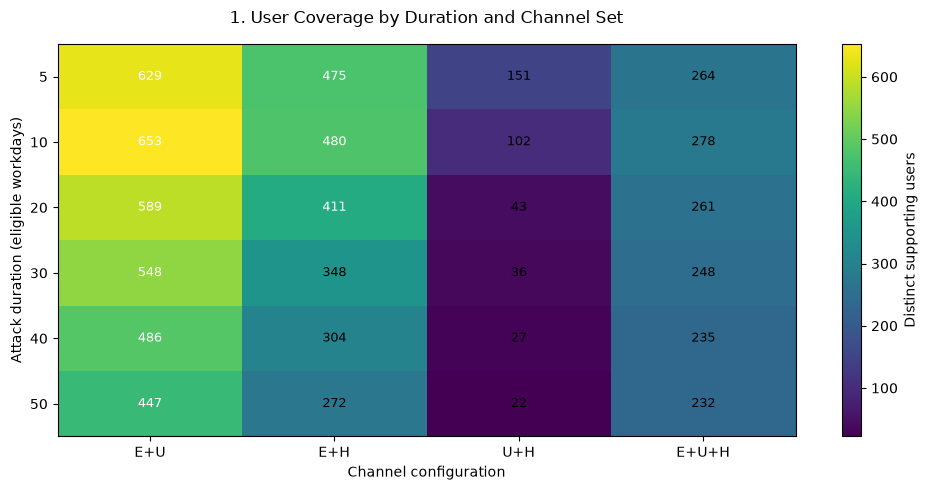

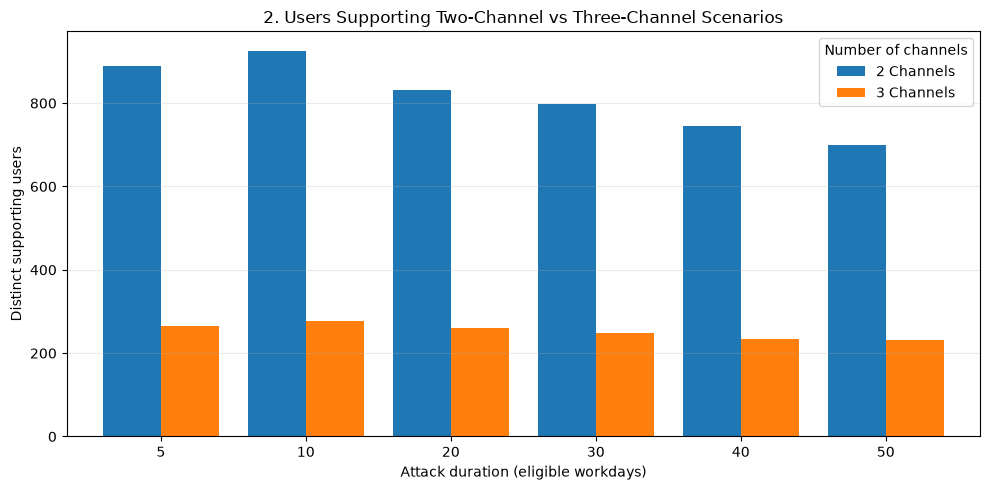

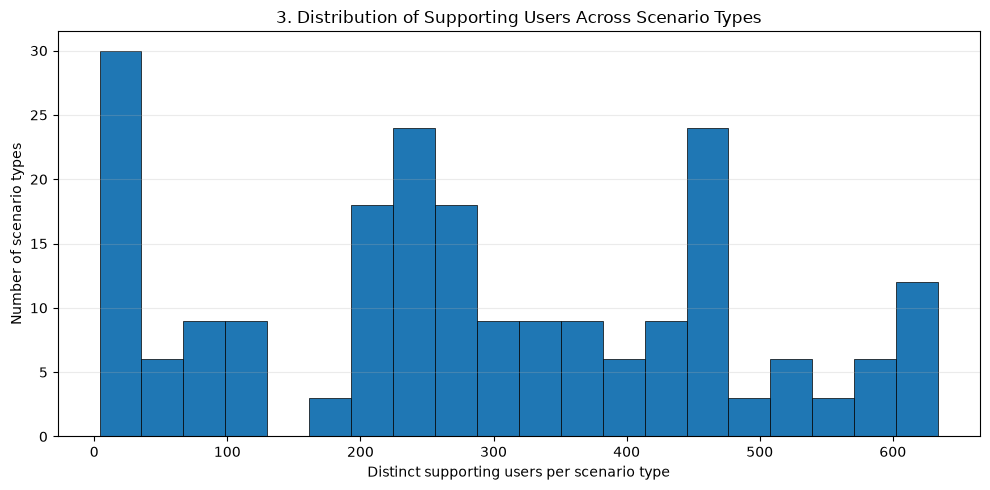

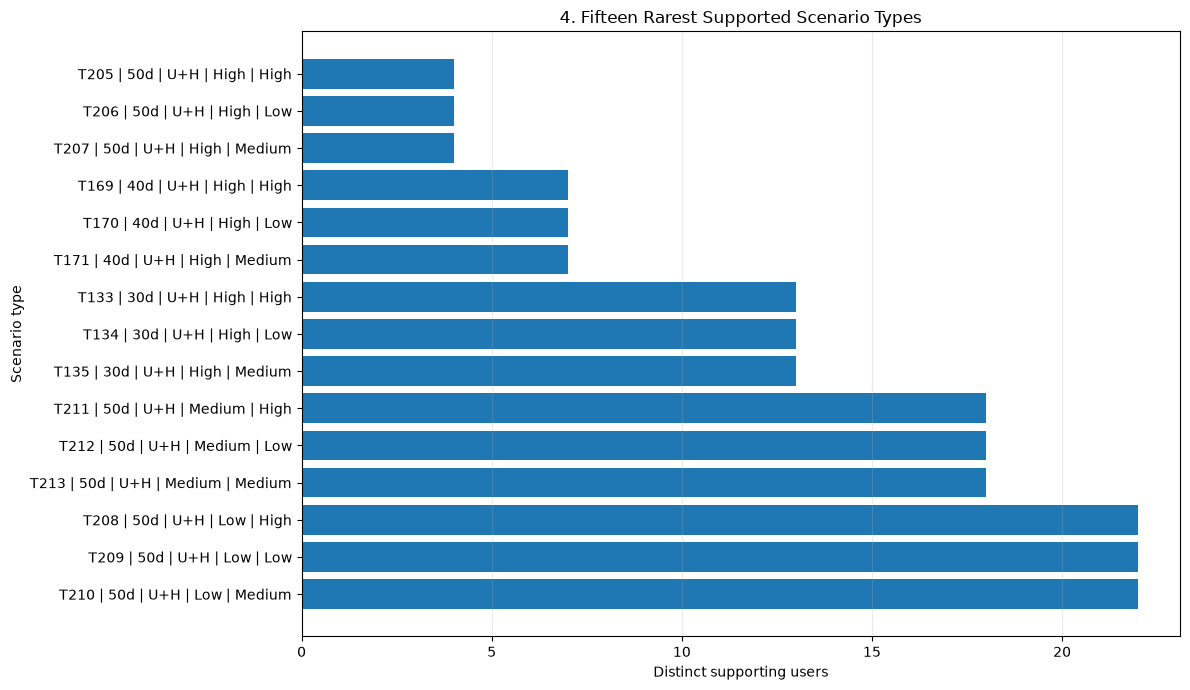

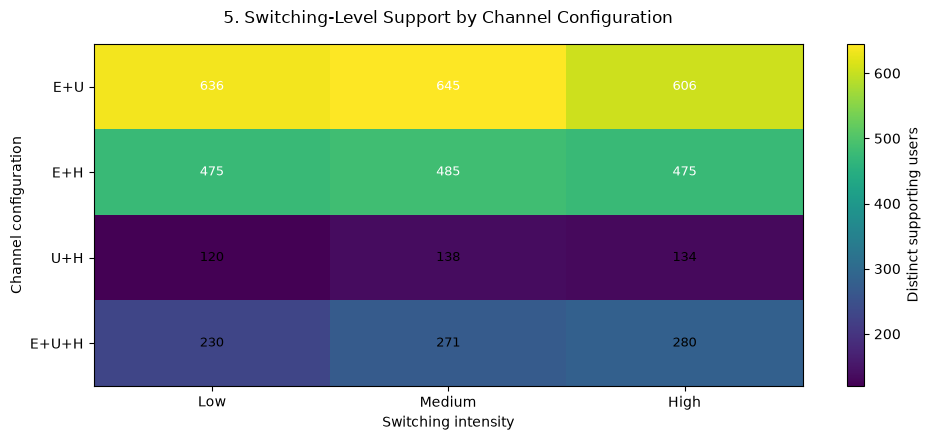


NOTEBOOK 07 — CELL 7.6
Catalog options        : 2,360,793
Supported scenario types: 213
Distinct candidate users: 936
Minimum users per type : 4
Median users per type  : 261.0
Maximum users per type : 634
Types with < 50 users  : 36
Types with < 100 users : 45
Visualizations generated: 5
Original QA recalculated: NO
Switching recalculated  : NO
Attackers assigned      : NO
Files written           : NO

CELL 7.6 — PASS


In [13]:

# ============================================================
# 7.6 — SCENARIO DIVERSITY COVERAGE & VISUALIZATION
#
# Analyze the QA-approved catalog only.
# Tables + 5 matplotlib figures inside Jupyter.
#
# No original feasibility recalculation
# No attacker assignment | No files written
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# ------------------------------------------------------------
# STEP 1 — Reuse QA-approved catalog
# ------------------------------------------------------------

assert "scenario_catalog_07" in globals()
assert "scenario_types_07" in globals()
assert "catalog_qa_pass_07" in globals()

assert catalog_qa_pass_07 == True, (
    "Catalog QA must pass before diversity analysis."
)

catalog_076 = scenario_catalog_07
types_076 = scenario_types_07

DURATIONS_076 = [5, 10, 20, 30, 40, 50]
CHANNELS_076 = ["E+U", "E+H", "U+H", "E+U+H"]
SWITCHING_076 = ["Low", "Medium", "High"]
STEALTH_076 = ["High", "Medium", "Low"]

print("STEP 1 — QA-approved catalog loaded: PASS")


# ------------------------------------------------------------
# STEP 2 — Scenario-type coverage
#
# Options count = available user-window alternatives.
# Users count = DISTINCT users supporting each type.
#
# No behavioral or switching feasibility recalculation.
# ------------------------------------------------------------

option_counts_076 = (
    catalog_076
    .groupby("scenario_type_id", observed=True)
    .size()
    .rename("available_options")
    .reset_index()
)

# Remove repeated windows/alternatives for the SAME
# user and scenario type before counting users.
user_type_support_076 = (
    catalog_076[
        ["scenario_type_id", "user"]
    ]
    .drop_duplicates()
)

user_counts_076 = (
    user_type_support_076
    .groupby("scenario_type_id", observed=True)
    .size()
    .rename("supporting_users")
    .reset_index()
)

scenario_type_coverage_07 = (
    types_076
    .merge(
        option_counts_076,
        on="scenario_type_id",
        validate="one_to_one"
    )
    .merge(
        user_counts_076,
        on="scenario_type_id",
        validate="one_to_one"
    )
)

assert len(scenario_type_coverage_07) == len(types_076)
assert scenario_type_coverage_07[
    "supporting_users"
].gt(0).all()

assert scenario_type_coverage_07[
    "available_options"
].ge(
    scenario_type_coverage_07["supporting_users"]
).all()

print("STEP 2 — Scenario-type coverage calculated: PASS")


# ------------------------------------------------------------
# STEP 3 — User-based diversity matrices
#
# Work with the compact unique user/type support,
# not every overlapping window.
# ------------------------------------------------------------

supported_types_076 = (
    user_type_support_076
    .merge(
        types_076,
        on="scenario_type_id",
        validate="many_to_one"
    )
)

# Duration × exact channel configuration
duration_channel_users_076 = (
    supported_types_076[
        ["user", "window_workdays", "channel_configuration"]
    ]
    .drop_duplicates()
    .groupby(
        ["window_workdays", "channel_configuration"],
        observed=True
    )
    .size()
    .unstack(fill_value=0)
    .reindex(
        index=DURATIONS_076,
        columns=CHANNELS_076,
        fill_value=0
    )
)

# Duration × channel count (2 or 3).
duration_channelcount_076 = (
    supported_types_076[
        ["user", "window_workdays", "channel_configuration"]
    ]
    .drop_duplicates()
    .assign(
        channel_count=lambda df:
            np.where(
                df["channel_configuration"].eq("E+U+H"),
                3,
                2
            )
    )
    [["user", "window_workdays", "channel_count"]]
    .drop_duplicates()
    .groupby(
        ["window_workdays", "channel_count"]
    )
    .size()
    .unstack(fill_value=0)
    .reindex(
        index=DURATIONS_076,
        columns=[2, 3],
        fill_value=0
    )
)

# Channel configuration × switching level.
channel_switch_users_076 = (
    supported_types_076[
        ["user", "channel_configuration", "switching_level"]
    ]
    .drop_duplicates()
    .groupby(
        ["channel_configuration", "switching_level"],
        observed=True
    )
    .size()
    .unstack(fill_value=0)
    .reindex(
        index=CHANNELS_076,
        columns=SWITCHING_076,
        fill_value=0
    )
)

print("STEP 3 — Distinct-user coverage matrices: PASS")


# ------------------------------------------------------------
# STEP 4 — Rare scenario types
# Rarity is ranked primarily by distinct users.
# ------------------------------------------------------------

rarest_types_07 = (
    scenario_type_coverage_07
    .sort_values(
        [
            "supporting_users",
            "available_options",
            "scenario_type_id"
        ],
        ascending=True
    )
    .head(15)
    .copy()
)

rarest_types_07["type_label"] = (
    "T"
    + rarest_types_07["scenario_type_id"].astype(str)
    + " | "
    + rarest_types_07["window_workdays"].astype(str)
    + "d | "
    + rarest_types_07["channel_configuration"].astype(str)
    + " | "
    + rarest_types_07["switching_level"].astype(str)
    + " | "
    + rarest_types_07["stealth_level"].astype(str)
)

print("STEP 4 — Rare scenario types identified: PASS")


# ------------------------------------------------------------
# STEP 5 — Numerical reports
# ------------------------------------------------------------

print("\nSCENARIO-TYPE COVERAGE SUMMARY")

display(
    scenario_type_coverage_07[
        [
            "scenario_type_id",
            "window_workdays",
            "channel_configuration",
            "switching_level",
            "stealth_level",
            "supporting_users",
            "available_options",
        ]
    ].sort_values(
        ["supporting_users", "scenario_type_id"]
    ).head(20)
)

print("\nDISTINCT USERS — DURATION × CHANNEL")
display(duration_channel_users_076)

print("\nDISTINCT USERS — DURATION × CHANNEL COUNT")
display(duration_channelcount_076)

print("\nDISTINCT USERS — CHANNEL × SWITCHING")
display(channel_switch_users_076)

print("\n15 RAREST SCENARIO TYPES")
display(
    rarest_types_07[
        [
            "scenario_type_id",
            "window_workdays",
            "channel_configuration",
            "switching_level",
            "stealth_level",
            "supporting_users",
            "available_options",
        ]
    ]
)


# ------------------------------------------------------------
# VISUALIZATION HELPER — Annotated heatmap
# ------------------------------------------------------------

def plot_heatmap_076(
    dataframe,
    title,
    xlabel,
    ylabel,
    figsize=(10, 5)
):
    fig, ax = plt.subplots(figsize=figsize)

    values = dataframe.to_numpy(dtype=float)

    image = ax.imshow(
        values,
        aspect="auto"
    )

    ax.set_xticks(np.arange(len(dataframe.columns)))
    ax.set_yticks(np.arange(len(dataframe.index)))

    ax.set_xticklabels(
        [str(x) for x in dataframe.columns]
    )

    ax.set_yticklabels(
        [str(x) for x in dataframe.index]
    )

    for i in range(values.shape[0]):
        for j in range(values.shape[1]):

            value = int(values[i, j])

            # Keep annotation readable against
            # varying heatmap backgrounds.
            color = (
                "white"
                if image.norm(value) > 0.55
                else "black"
            )

            ax.text(
                j,
                i,
                f"{value:,}",
                ha="center",
                va="center",
                color=color,
                fontsize=9
            )

    ax.set_title(title, pad=15)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)

    fig.colorbar(
        image,
        ax=ax,
        label="Distinct supporting users"
    )

    plt.tight_layout()
    plt.show()


# ------------------------------------------------------------
# CHART 1 — Duration × channel configuration
# ------------------------------------------------------------

plot_heatmap_076(
    duration_channel_users_076,
    title="1. User Coverage by Duration and Channel Set",
    xlabel="Channel configuration",
    ylabel="Attack duration (eligible workdays)"
)


# ------------------------------------------------------------
# CHART 2 — Two-channel vs three-channel support
#
# A user can be counted in both groups because
# they may support both configurations.
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 5))

duration_channelcount_076.plot(
    kind="bar",
    ax=ax,
    width=0.8
)

ax.set_title(
    "2. Users Supporting Two-Channel vs Three-Channel Scenarios"
)

ax.set_xlabel("Attack duration (eligible workdays)")
ax.set_ylabel("Distinct supporting users")
ax.legend(
    title="Number of channels",
    labels=["2 Channels", "3 Channels"]
)

ax.grid(axis="y", alpha=0.25)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# CHART 3 — Distribution of user support per scenario type
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 5))

ax.hist(
    scenario_type_coverage_07[
        "supporting_users"
    ],
    bins=20,
    edgecolor="black",
    linewidth=0.5
)

ax.set_title(
    "3. Distribution of Supporting Users Across Scenario Types"
)

ax.set_xlabel(
    "Distinct supporting users per scenario type"
)

ax.set_ylabel("Number of scenario types")

ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# CHART 4 — 15 rarest scenario types
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 7))

plot_data_076 = rarest_types_07.iloc[::-1]

ax.barh(
    plot_data_076["type_label"],
    plot_data_076["supporting_users"]
)

ax.set_title(
    "4. Fifteen Rarest Supported Scenario Types"
)

ax.set_xlabel("Distinct supporting users")
ax.set_ylabel("Scenario type")

ax.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# CHART 5 — Channel configuration × switching level
# ------------------------------------------------------------

plot_heatmap_076(
    channel_switch_users_076,
    title="5. Switching-Level Support by Channel Configuration",
    xlabel="Switching intensity",
    ylabel="Channel configuration",
    figsize=(10, 4.5)
)


# ------------------------------------------------------------
# STEP 6 — Consolidated interpretation metrics
# ------------------------------------------------------------

support_stats_076 = (
    scenario_type_coverage_07[
        "supporting_users"
    ]
)

print("\n" + "=" * 65)
print("NOTEBOOK 07 — CELL 7.6")
print("=" * 65)

print(
    "Catalog options        :",
    f"{len(catalog_076):,}"
)

print(
    "Supported scenario types:",
    len(scenario_type_coverage_07)
)

print(
    "Distinct candidate users:",
    catalog_076["user"].nunique()
)

print(
    "Minimum users per type :",
    int(support_stats_076.min())
)

print(
    "Median users per type  :",
    f"{support_stats_076.median():.1f}"
)

print(
    "Maximum users per type :",
    int(support_stats_076.max())
)

print(
    "Types with < 50 users  :",
    int(support_stats_076.lt(50).sum())
)

print(
    "Types with < 100 users :",
    int(support_stats_076.lt(100).sum())
)

print("Visualizations generated: 5")
print("Original QA recalculated: NO")
print("Switching recalculated  : NO")
print("Attackers assigned      : NO")
print("Files written           : NO")

print("\nCELL 7.6 — PASS")



### 7.6.1 — Diversity Analysis: Results & Interpretation

#### Overall Results

The diversity analysis confirmed that the validated catalog contains:

- **2,360,793 scenario options** across **936 candidate users**.
- **213 supported scenario types** out of 216 theoretical combinations.
- **36 scenario types** supported by fewer than 50 users.
- **109 scenario types** supported by fewer than 100 users.
- **4 users** supporting the rarest scenario type.
- **261 users** as the median support per scenario type.
- **634 users** supporting the most widely available scenario type.

These results demonstrate broad scenario diversity but uneven availability across different configurations.

**Important:** Scenario options represent user-window alternatives, not independent attackers. Distinct supporting users are therefore more meaningful than the total number of options when planning attacker selection.

---

#### Figure 1 — User Coverage by Duration and Channel Set

The first heatmap shows the number of distinct users supporting each combination of attack duration and channel configuration.

**Key Findings:**

- **E+U** has the broadest coverage, ranging from 447 to 653 users across the six durations.
- **E+H** also has substantial coverage, ranging from 272 to 480 users.
- **E+U+H** remains available across all durations, with 232–278 supporting users.
- **U+H** has the lowest availability, declining from 151 users at 5 days to only 22 at 50 days.

**Interpretation:** All four channel configurations are represented, but availability is highly uneven. Long-duration U+H scenarios are particularly constrained and should be considered during diversity-aware assignment.

---

#### Figure 2 — Two-Channel vs. Three-Channel Support

The grouped bar chart compares distinct users capable of supporting at least one two-channel or three-channel scenario for each duration.

**Key Findings:**

- Two-channel scenarios are supported by **699–926 users**, depending on duration.
- Three-channel scenarios are supported by **232–278 users**.
- Both categories remain available across all six durations.
- Longer durations generally reduce the number of supporting users.

**Interpretation:** The catalog supports diversity in channel count, including long-duration three-channel scenarios. However, three-channel availability is more limited and must be considered when selecting the final 400 attackers.

A user may appear in both categories; the bars do not represent mutually exclusive user populations.

---

#### Figure 3 — Distribution of Supporting Users Across Scenario Types

The histogram illustrates how many distinct users support each of the 213 scenario types.

**Key Findings:**

- Scenario-type availability ranges from **4 to 634 users**.
- Median availability is **261 users per type**.
- **36 types** have fewer than 50 supporting users.
- **109 types** have fewer than 100 supporting users.

**Interpretation:** Scenario availability is not uniformly distributed. Although the catalog contains many alternatives, some scenario types depend on very small groups of users.

Consequently, assignment decisions should consider distinct-user availability rather than relying on the overall number of catalog options.

---

#### Figure 4 — Fifteen Rarest Supported Scenario Types

The horizontal bar chart identifies the 15 scenario types with the fewest supporting users.

**Key Findings:**

- The rarest configurations involve **U+H**, particularly with long durations and High Switching.
- **50 days + U+H + High Switching** is supported by only **4 users**.
- **40 days + U+H + High Switching** is supported by **7 users**.
- **30 days + U+H + High Switching** is supported by **13 users**.
- The same configurations appear under different stealth levels because all three approved stealth levels were applied to each supported switching option.

**Interpretation:** Long-duration U+H configurations are the most constrained scenario categories.

These rare combinations should receive particular attention during attacker assignment to avoid allocating their limited supporting users exclusively to common configurations.

The repeated stealth variants must not be interpreted as independent groups of users.

---

#### Figure 5 — Switching-Level Support by Channel Configuration

The second heatmap presents distinct-user availability across channel configurations and switching intensities.

| Channel Configuration | Low | Medium | High |
|---|---:|---:|---:|
| E+U | 636 | 645 | 606 |
| E+H | 475 | 485 | 475 |
| U+H | 120 | 138 | 134 |
| E+U+H | 230 | 271 | 280 |

**Key Findings:**

- All three switching levels are represented across the four channel configurations.
- **E+U** has the largest supporting population across all switching levels.
- **U+H** consistently has the smallest supporting population.
- Three-channel configurations support all switching levels across the overall catalog, although the five-day Low-Switching combination is infeasible.

**Interpretation:** Switching diversity is broadly available. The main challenge is not the absence of individual switching levels, but the limited availability of certain combinations involving duration, channel configuration, and switching intensity.

The same user can support multiple switching levels and should not be counted as a separate attacker in each category.

---

#### Implications for Notebook 08 — Attacker Assignment

The diversity analysis provides several considerations for selecting the final 400 attackers:

1. **Preserve Duration Diversity:** Include short, medium, and long attack durations, representing all six approved duration categories where feasible.
2. **Preserve Channel Diversity:** Represent two-channel and three-channel attacks, including different two-channel combinations.
3. **Preserve Switching Diversity:** Include Low, Medium, and High Switching across supported configurations.
4. **Preserve Stealth Diversity:** Distribute High, Medium, and Low Stealth without changing the approved Formula A + Balanced configuration.
5. **Prioritize Rare Configurations:** Consider users supporting rare scenario types before assigning them to widely available alternatives.
6. **Avoid Double-Counting Users:** Each selected attacker must be treated as one distinct user regardless of the number of supported scenario options.
7. **Prefer Fewer Forced Off-Days:** Among suitable alternatives, prioritize windows with fewer forced Off-Days while preserving all approved feasibility constraints.

#### Limitations

- Coverage figures describe available options, not a finalized allocation of 400 attackers.
- Supporting-user counts overlap across durations, channel configurations, and switching levels.
- The 213 supported types do not guarantee that all types can be represented simultaneously under a one-scenario-per-user assignment.
- Exact daily channel sequences, final switch counts, and injection schedules have not yet been selected.
- Diversity analysis does not evaluate MUBSIR's detection performance.

#### Conclusion

The validated scenario catalog provides broad diversity across attack duration, channel configuration, switching intensity, and stealth level.

However, user availability is uneven, particularly for long-duration U+H scenarios.

These findings support a **diversity-aware, rarity-conscious attacker assignment strategy** for Notebook 08, while preserving previously validated feasibility and avoiding premature selection of users or attack windows.



## 7.7 — Final Catalog Export & Handoff

### Objective
Export the QA-approved, diversity-aware scenario catalog and supporting documentation for use in Notebook 08 — Attacker Selection & Scenario Assignment.

### Approved Inputs
- `scenario_catalog_07` — validated user-window scenario options.
- `scenario_types_07` — distinct scenario-type definitions.
- `scenario_type_coverage_07` — scenario-type availability and distinct-user coverage.
- `rarest_types_07` — rare scenario types identified in Section 7.6.
- `catalog_qa_07` and `catalog_qa_pass_07` — approved catalog QA results.
- `stealth_rule_07` — selected Formula A + Balanced configuration.

### Procedure
1. Confirm that the previously completed catalog QA was approved.
2. Export the complete scenario-option catalog in Parquet format.
3. Export the scenario-type reference table.
4. Export the diversity coverage results.
5. Generate a data dictionary describing the exported columns.
6. Document the diversity findings, rare configurations, and assignment considerations.
7. Confirm that all required deliverables were written and are readable.

### Final Deliverables
- `feasible_scenario_catalog.parquet`
- `scenario_types.parquet`
- `scenario_diversity_coverage.csv`
- `scenario_catalog_dictionary.csv`
- `scenario_diversity_report.md`

The two previously exported QA files will remain unchanged:
- `scenario_catalog_qa.csv`
- `scenario_catalog_qa_report.md`

### Handoff Requirements
- Preserve all user-window alternatives.
- Preserve scenario type and option identifiers.
- Preserve exact switching-count bitmasks and their proof sources.
- Preserve approved duration, channel, switching, and stealth configurations.
- Do not select the final 400 attackers.
- Do not finalize daily channel sequences or injection counts.
- Do not modify the historical Baseline or original datasets.

### Expected Outcome
A complete, documented, and readable catalog package ready for Notebook 08, without repeating previously completed analyses or validation procedures.


In [16]:

# ============================================================
# NOTEBOOK 07 — SECTION 7.7
# FINAL CATALOG EXPORT, DOCUMENTATION & HANDOFF
#
# Outputs:
#   1. feasible_scenario_catalog.parquet
#   2. scenario_types.parquet
#   3. scenario_diversity_coverage.csv
#   4. scenario_catalog_dictionary.csv
#   5. scenario_diversity_report.md
#
# Existing QA reports are preserved:
#   6. scenario_catalog_qa.csv
#   7. scenario_catalog_qa_report.md
#
# No source modification
# No scenario recalculation
# No switching DP recalculation
# No attacker assignment
# No backup files
# ============================================================

from pathlib import Path
import pandas as pd
import pyarrow.parquet as pq
from IPython.display import display


# ============================================================
# STEP 1 — LOAD PREVIOUSLY APPROVED RESULTS
# ============================================================

required_objects_077 = [
    "ROOT",
    "scenario_catalog_07",
    "scenario_types_07",
    "scenario_type_coverage_07",
    "rarest_types_07",
    "duration_channel_users_076",
    "duration_channelcount_076",
    "channel_switch_users_076",
    "catalog_qa_07",
    "catalog_qa_pass_07",
    "stealth_rule_07",
]

missing_objects_077 = [
    name
    for name in required_objects_077
    if name not in globals()
]

assert not missing_objects_077, (
    f"Missing previous notebook results: {missing_objects_077}"
)

assert bool(catalog_qa_pass_07), (
    "Previously completed catalog QA was not approved."
)

assert len(catalog_qa_07) == 33
assert catalog_qa_07["Status"].eq("PASS").all()

# Reuse original in-memory objects without modification.
catalog_077 = scenario_catalog_07
types_077 = scenario_types_07
coverage_077 = scenario_type_coverage_07
rarest_077 = rarest_types_07
stealth_077 = stealth_rule_07

# Compare against already confirmed results.
assert len(catalog_077) == 2_360_793
assert len(types_077) == 213
assert len(coverage_077) == 213
assert catalog_077["user"].nunique() == 936

assert stealth_077["formula_id"] == "A"
assert stealth_077["configuration"] == "Balanced"

print("STEP 1 — Approved notebook results loaded: PASS")


# ============================================================
# STEP 2 — PREPARE OUTPUT DIRECTORY AND PATHS
# ============================================================

REPORT_077 = (
    Path(ROOT)
    / "reports"
    / "07_Scenario_Design_and_Feasible_Catalog"
)

REPORT_077.mkdir(
    parents=True,
    exist_ok=True,
)

CATALOG_PATH_077 = (
    REPORT_077 / "feasible_scenario_catalog.parquet"
)

TYPES_PATH_077 = (
    REPORT_077 / "scenario_types.parquet"
)

COVERAGE_PATH_077 = (
    REPORT_077 / "scenario_diversity_coverage.csv"
)

DICTIONARY_PATH_077 = (
    REPORT_077 / "scenario_catalog_dictionary.csv"
)

DIVERSITY_REPORT_PATH_077 = (
    REPORT_077 / "scenario_diversity_report.md"
)

QA_CSV_PATH_077 = (
    REPORT_077 / "scenario_catalog_qa.csv"
)

QA_REPORT_PATH_077 = (
    REPORT_077 / "scenario_catalog_qa_report.md"
)

# The previously approved QA reports must already exist.
assert QA_CSV_PATH_077.is_file(), (
    "Missing previously exported QA CSV report."
)

assert QA_REPORT_PATH_077.is_file(), (
    "Missing previously exported QA Markdown report."
)

# These reports will NOT be overwritten.
print("STEP 2 — Output directory and QA reports: PASS")


# ============================================================
# STEP 3 — EXPORT APPROVED SCENARIO CATALOG
# ============================================================

catalog_077.to_parquet(
    CATALOG_PATH_077,
    index=False,
    engine="pyarrow",
    compression="zstd",
)

types_077.to_parquet(
    TYPES_PATH_077,
    index=False,
    engine="pyarrow",
    compression="zstd",
)

print("STEP 3 — Scenario catalog and types exported: PASS")


# ============================================================
# STEP 4 — EXPORT SCENARIO DIVERSITY COVERAGE
# ============================================================

# Reuse Section 7.6 results directly.
# No groupby, switching analysis, or candidate recalculation.

coverage_077.to_csv(
    COVERAGE_PATH_077,
    index=False,
    encoding="utf-8-sig",
)

print("STEP 4 — Scenario diversity coverage exported: PASS")


# ============================================================
# STEP 5 — COMPREHENSIVE OUTPUT DATA DICTIONARY
#
# Documents:
#   - All final structured export files
#   - QA CSV
#   - Both Markdown reports
#   - The dictionary itself
#   - Five visualizations within Section 7.6
#
# Record types:
#   ARTIFACT = complete file/output description
#   COLUMN   = individual structured data column
# ============================================================

descriptions_077 = {

    # --------------------------------------------------------
    # Identifiers
    # --------------------------------------------------------

    "scenario_option_id":
        "Unique identifier for one user-window scenario option.",

    "scenario_type_id":
        "Identifier of a supported duration-channel-switching-stealth scenario type.",

    "user":
        "Original CERT r6.2 user identifier.",

    # --------------------------------------------------------
    # Attack window
    # --------------------------------------------------------

    "window_workdays":
        "Attack duration measured in eligible workdays.",

    "window_start":
        "Start date of the approved user-specific attack window.",

    "window_end":
        "End date of the approved user-specific attack window.",

    "proposed_active_days":
        "Number of proposed attack-active days inherited from the approved structural window.",

    "forced_offdays":
        "Number of forced non-injection days in the approved window.",

    # --------------------------------------------------------
    # Channel and switching configuration
    # --------------------------------------------------------

    "channel_configuration":
        "Selected channel set: E+U, E+H, U+H, or E+U+H.",

    "channel_count":
        "Number of selected attack channels: two or three.",

    "switching_level":
        "Approved switching intensity: Low, Medium, or High.",

    "set_switch_bitmask":
        "Bitset of attainable exact switch counts for the selected channel set. Bit k indicates k switches.",

    "proof_source":
        "Source of the exact selected-channel switching feasibility proof.",

    # --------------------------------------------------------
    # Stealth
    # --------------------------------------------------------

    "stealth_level":
        "Approved injection stealth level: High, Medium, or Low.",

    "stealth_multiplier":
        "Approved Balanced multiplier associated with the stealth level.",

    "formula_id":
        "Approved historical P95-based injection-count formula identifier: A.",

    "multiplier_configuration":
        "Approved multiplier configuration: Balanced.",

    # --------------------------------------------------------
    # Catalog status
    # --------------------------------------------------------

    "catalog_status":
        "Current scenario-catalog status; daily attack assignment has not been finalized.",

    # --------------------------------------------------------
    # Diversity coverage
    # --------------------------------------------------------

    "available_options":
        "Number of available user-window scenario alternatives supporting a scenario type.",

    "supporting_users":
        "Number of distinct users capable of supporting a scenario type.",

    # --------------------------------------------------------
    # Catalog QA
    # --------------------------------------------------------

    "Check":
        "Name of the catalog integrity or traceability validation.",

    "Status":
        "Recorded validation outcome, such as PASS or FAIL.",

    "Details":
        "Explanation or supporting details for the validation result.",
}


artifact_inventory_077 = [

    {
        "file": "feasible_scenario_catalog.parquet",
        "artifact_type": "Parquet",
        "description":
            "Complete validated user-window-channel-switching-stealth "
            "scenario option catalog for Notebook 08.",
        "dataframe": catalog_077,
    },

    {
        "file": "scenario_types.parquet",
        "artifact_type": "Parquet",
        "description":
            "Reference definitions for the 213 supported scenario types.",
        "dataframe": types_077,
    },

    {
        "file": "scenario_diversity_coverage.csv",
        "artifact_type": "CSV",
        "description":
            "Scenario-type diversity coverage including distinct supporting "
            "users and available user-window options.",
        "dataframe": coverage_077,
    },

    {
        "file": "scenario_catalog_qa.csv",
        "artifact_type": "CSV",
        "description":
            "Detailed results of the 33 previously approved catalog "
            "integrity and traceability checks.",
        "dataframe": catalog_qa_07,
    },

    {
        "file": "scenario_catalog_qa_report.md",
        "artifact_type": "Markdown",
        "description":
            "Narrative report documenting the catalog QA scope, "
            "results, limitations, and approval decision.",
        "dataframe": None,
    },

    {
        "file": "scenario_diversity_report.md",
        "artifact_type": "Markdown",
        "description":
            "Scenario availability, diversity analysis, rare scenario "
            "types, visualization findings, and Notebook 08 implications.",
        "dataframe": None,
    },

    {
        "file": "scenario_catalog_dictionary.csv",
        "artifact_type": "CSV",
        "description":
            "Comprehensive dictionary of Notebook 07 deliverables, "
            "report artifacts, and structured data columns.",
        "dataframe": None,
    },

    {
        "file": "Section 7.6 — Jupyter Visualizations",
        "artifact_type": "Notebook Figures",
        "description":
            "Five in-notebook visualizations: duration/channel coverage, "
            "two-channel versus three-channel support, user-support "
            "distribution, rare scenario types, and switching-level "
            "coverage. These figures are not exported as image files.",
        "dataframe": None,
    },
]


dictionary_rows_077 = []

for artifact in artifact_inventory_077:

    filename = artifact["file"]
    artifact_type = artifact["artifact_type"]
    artifact_description = artifact["description"]
    frame = artifact["dataframe"]

    # File-level / artifact-level record.
    dictionary_rows_077.append({
        "record_type": "ARTIFACT",
        "file": filename,
        "artifact_type": artifact_type,
        "column": "",
        "dtype": "",
        "description": artifact_description,
    })

    # Column-level records for structured datasets.
    if frame is not None:

        for column in frame.columns:

            assert column in descriptions_077, (
                f"Missing dictionary definition: "
                f"{filename} / {column}"
            )

            dictionary_rows_077.append({
                "record_type": "COLUMN",
                "file": filename,
                "artifact_type": artifact_type,
                "column": column,
                "dtype": str(frame[column].dtype),
                "description": descriptions_077[column],
            })


scenario_dictionary_07 = pd.DataFrame(
    dictionary_rows_077
)

assert not scenario_dictionary_07.duplicated(
    ["record_type", "file", "column"]
).any()

scenario_dictionary_07.to_csv(
    DICTIONARY_PATH_077,
    index=False,
    encoding="utf-8-sig",
)

dictionary_artifacts_077 = int(
    scenario_dictionary_07["record_type"].eq("ARTIFACT").sum()
)

dictionary_columns_077 = int(
    scenario_dictionary_07["record_type"].eq("COLUMN").sum()
)

print("STEP 5 — Comprehensive output dictionary exported: PASS")

print(
    f"         Documented artifacts: {dictionary_artifacts_077}"
)

print(
    f"         Documented columns  : {dictionary_columns_077}"
)


# ============================================================
# STEP 6 — GENERATE SCENARIO DIVERSITY REPORT
#
# Reuse existing Section 7.6 results.
# No additional diversity or feasibility calculation.
# ============================================================

def markdown_table_077(headers, rows):
    """Convert existing tabular results into Markdown."""

    def clean(value):
        return (
            str(value)
            .replace("|", "\\|")
            .replace("\n", " ")
        )

    lines = [
        "| " + " | ".join(map(clean, headers)) + " |",
        "| " + " | ".join(["---"] * len(headers)) + " |",
    ]

    for row in rows:
        lines.append(
            "| " + " | ".join(map(clean, row)) + " |"
        )

    return "\n".join(lines)


# ------------------------------------------------------------
# 6.1 — Duration × channel coverage
# ------------------------------------------------------------

duration_rows_077 = [
    [
        int(duration),
        int(row["E+U"]),
        int(row["E+H"]),
        int(row["U+H"]),
        int(row["E+U+H"]),
    ]
    for duration, row
    in duration_channel_users_076.iterrows()
]

duration_table_077 = markdown_table_077(
    [
        "Duration",
        "E+U",
        "E+H",
        "U+H",
        "E+U+H",
    ],
    duration_rows_077,
)


# ------------------------------------------------------------
# 6.2 — Two-channel vs three-channel coverage
# ------------------------------------------------------------

channel_count_rows_077 = [
    [
        int(duration),
        int(row[2]),
        int(row[3]),
    ]
    for duration, row
    in duration_channelcount_076.iterrows()
]

channel_count_table_077 = markdown_table_077(
    [
        "Duration",
        "Two Channels",
        "Three Channels",
    ],
    channel_count_rows_077,
)


# ------------------------------------------------------------
# 6.3 — Switching coverage
# ------------------------------------------------------------

switch_rows_077 = [
    [
        channel,
        int(row["Low"]),
        int(row["Medium"]),
        int(row["High"]),
    ]
    for channel, row
    in channel_switch_users_076.iterrows()
]

switch_table_077 = markdown_table_077(
    [
        "Channel Configuration",
        "Low",
        "Medium",
        "High",
    ],
    switch_rows_077,
)


# ------------------------------------------------------------
# 6.4 — Rare scenario types
# ------------------------------------------------------------

rare_rows_077 = [
    [
        int(row.scenario_type_id),
        int(row.window_workdays),
        str(row.channel_configuration),
        str(row.switching_level),
        str(row.stealth_level),
        int(row.supporting_users),
        int(row.available_options),
    ]
    for row in rarest_077.itertuples(index=False)
]

rare_table_077 = markdown_table_077(
    [
        "Scenario Type",
        "Duration",
        "Channels",
        "Switching",
        "Stealth",
        "Supporting Users",
        "Available Options",
    ],
    rare_rows_077,
)


# ------------------------------------------------------------
# 6.5 — Reuse previously calculated coverage statistics
# ------------------------------------------------------------

user_support_077 = coverage_077["supporting_users"]

min_support_077 = int(user_support_077.min())
median_support_077 = float(user_support_077.median())
max_support_077 = int(user_support_077.max())

under_50_077 = int(user_support_077.lt(50).sum())
under_100_077 = int(user_support_077.lt(100).sum())


# ------------------------------------------------------------
# 6.6 — Markdown report
# ------------------------------------------------------------

diversity_report_077 = f"""# MUBSIR — Notebook 07
## Scenario Diversity Coverage Report

### 1. Objective

Analyze the availability and diversity of validated scenario
options to support the selection of 400 distinct attackers
in Notebook 08.

All numerical findings are reused from Section 7.6.

### 2. Validated Catalog Overview

- **Catalog options:** {len(catalog_077):,}
- **Supported scenario types:** {len(types_077):,}
- **Theoretical scenario types:** 216
- **Distinct candidate users:** 936
- **Catalog QA:** 33/33 PASS
- **Attack durations:** 5, 10, 20, 30, 40, 50 workdays
- **Channel configurations:** E+U, E+H, U+H, E+U+H
- **Switching levels:** Low, Medium, High
- **Stealth levels:** High, Medium, Low
- **Injection rule:** Formula A + Balanced

### 3. Overall Diversity Findings

- **Minimum supporting users per type:** {min_support_077}
- **Median supporting users per type:** {median_support_077:.1f}
- **Maximum supporting users per type:** {max_support_077}
- **Types with fewer than 50 users:** {under_50_077}
- **Types with fewer than 100 users:** {under_100_077}

The availability of scenario types is uneven.

Distinct supporting users are the main availability measure
because overlapping windows do not represent independent attackers.

### 4. Figure 1 — User Coverage by Duration and Channel Set

{duration_table_077}

**Interpretation**

- E+U has broad availability across all six durations.
- E+H and E+U+H are also represented throughout.
- U+H has the lowest availability, especially for long attacks.
- Supporting-user counts overlap across configurations.

### 5. Figure 2 — Two-Channel vs. Three-Channel Support

{channel_count_table_077}

**Interpretation**

- Both two-channel and three-channel scenarios remain available
  across all six durations.
- Two-channel scenarios have a larger supporting population.
- Users may qualify for both channel-count categories.

### 6. Figure 3 — Distribution of User Support

Scenario-type availability ranges from {min_support_077}
to {max_support_077} distinct users.

The median is {median_support_077:.1f} users per type.

There are {under_50_077} types supported by fewer than
50 users and {under_100_077} types supported by fewer
than 100 users.

**Interpretation**

The catalog provides broad diversity, but some scenario types
are much more constrained than others.

Selection should account for the availability of distinct users,
not only the number of user-window alternatives.

### 7. Figure 4 — Fifteen Rarest Scenario Types

{rare_table_077}

**Interpretation**

The rarest supported scenarios concentrate on long-duration
U+H configurations, particularly High Switching.

Repeated stealth variants can depend on the same supporting
users and must not be treated as independent user populations.

These rare combinations deserve consideration during
diversity-aware attacker assignment.

### 8. Figure 5 — Switching-Level Coverage

{switch_table_077}

**Interpretation**

Low, Medium, and High Switching are represented in all four
channel configurations across the overall catalog.

The main limitation arises from specific combinations of
duration, channel configuration, and switching intensity.

### 9. Unsupported Theoretical Scenario Types

Three theoretical scenario types are unsupported:

- 5 days + E+U+H + Low Switching + High Stealth
- 5 days + E+U+H + Low Switching + Medium Stealth
- 5 days + E+U+H + Low Switching + Low Stealth

A three-channel attack requires at least two switches,
whereas the five-day Low Switching exception requires
exactly one switch.

### 10. Implications for Notebook 08

The selection stage should:

1. Select 400 distinct users from the approved candidate pool.
2. Preserve diversity across all six attack durations.
3. Represent different two-channel combinations.
4. Represent three-channel scenarios.
5. Represent Low, Medium, and High Switching.
6. Distribute the approved stealth levels.
7. Consider rare supported scenario types during assignment.
8. Avoid counting the same user as multiple attackers.
9. Prefer fewer forced Off-Days when suitable alternatives exist.
10. Preserve all previously approved feasibility constraints.

These are assignment objectives, not completed assignments.

### 11. Interpretation Boundaries

- Scenario options are not finalized attacks.
- Multiple options can belong to the same user.
- Coverage does not guarantee simultaneous representation
  of all 213 scenario types among 400 attackers.
- Exact switch counts and daily channel schedules
  remain unassigned.
- No injection or detection-performance evaluation
  was performed in Notebook 07.
- The five visualizations remain in the Jupyter notebook;
  this report records their numerical findings and interpretation.

### 12. Handoff Decision

The validated catalog, scenario-type definitions,
diversity coverage, comprehensive dictionary, and
previously approved QA reports are prepared for Notebook 08.

**Catalog QA: PASS**

**Attacker assignment: NOT STARTED**

**Injection: NOT PERFORMED**

No original source data or historical Baseline was modified.
"""

DIVERSITY_REPORT_PATH_077.write_text(
    diversity_report_077,
    encoding="utf-8",
)

print("STEP 6 — Scenario diversity report exported: PASS")


# ============================================================
# STEP 7 — VERIFY EXPORTED FILES
#
# Only verify saved output files and readability.
# Do not repeat previously completed catalog QA.
# ============================================================

required_files_077 = [
    CATALOG_PATH_077,
    TYPES_PATH_077,
    COVERAGE_PATH_077,
    DICTIONARY_PATH_077,
    DIVERSITY_REPORT_PATH_077,
    QA_CSV_PATH_077,
    QA_REPORT_PATH_077,
]

# ------------------------------------------------------------
# 7.1 — File presence and non-empty size
# ------------------------------------------------------------

for path in required_files_077:

    assert path.is_file(), (
        f"Missing export: {path.name}"
    )

    assert path.stat().st_size > 0, (
        f"Empty export: {path.name}"
    )


# ------------------------------------------------------------
# 7.2 — Parquet metadata verification
# Avoid loading the 2.36M-row catalog again.
# ------------------------------------------------------------

catalog_metadata_077 = pq.read_metadata(
    CATALOG_PATH_077
)

types_metadata_077 = pq.read_metadata(
    TYPES_PATH_077
)

assert catalog_metadata_077.num_rows == len(catalog_077)

assert types_metadata_077.num_rows == len(types_077)

assert (
    pq.read_schema(CATALOG_PATH_077).names
    == catalog_077.columns.tolist()
)

assert (
    pq.read_schema(TYPES_PATH_077).names
    == types_077.columns.tolist()
)


# ------------------------------------------------------------
# 7.3 — CSV read-back verification
# ------------------------------------------------------------

saved_coverage_077 = pd.read_csv(
    COVERAGE_PATH_077
)

saved_dictionary_077 = pd.read_csv(
    DICTIONARY_PATH_077
)

assert len(saved_coverage_077) == len(coverage_077)

assert (
    saved_coverage_077.columns.tolist()
    == coverage_077.columns.tolist()
)

assert len(saved_dictionary_077) == len(
    scenario_dictionary_07
)

assert (
    saved_dictionary_077["record_type"]
    .eq("ARTIFACT")
    .sum()
    == dictionary_artifacts_077
)

assert (
    saved_dictionary_077["record_type"]
    .eq("COLUMN")
    .sum()
    == dictionary_columns_077
)


# ------------------------------------------------------------
# 7.4 — Markdown report read-back
# ------------------------------------------------------------

saved_report_077 = (
    DIVERSITY_REPORT_PATH_077.read_text(
        encoding="utf-8"
    )
)

assert "Scenario Diversity Coverage Report" in saved_report_077
assert "Notebook 08" in saved_report_077
assert "Figure 5" in saved_report_077

# Verify QA report preservation.
assert QA_CSV_PATH_077.is_file()
assert QA_REPORT_PATH_077.is_file()

print("STEP 7 — Export file/read-back verification: PASS")


# ============================================================
# STEP 8 — FINAL EXPORT SUMMARY
# ============================================================

print("\n" + "=" * 68)
print("NOTEBOOK 07 — CELL 7.7")
print("FINAL CATALOG EXPORT & HANDOFF")
print("=" * 68)

print(
    f"Catalog options exported  : "
    f"{catalog_metadata_077.num_rows:,}"
)

print(
    f"Scenario types exported   : "
    f"{types_metadata_077.num_rows:,}"
)

print(
    f"Coverage records exported : "
    f"{len(saved_coverage_077):,}"
)

print(
    f"Documented artifacts      : "
    f"{dictionary_artifacts_077}"
)

print(
    f"Documented columns        : "
    f"{dictionary_columns_077}"
)

print("Catalog QA                : 33/33 PASS")
print("New files exported        : 5")
print("Existing QA files         : 2")
print("Total files present       : 7")

print("\nPROCESS STATUS")
print("-" * 68)

print("Original QA recalculated  : NO")
print("Behavior recalculated     : NO")
print("Switching DP recalculated : NO")
print("Attacker assignment       : NOT STARTED")
print("Injection performed       : NO")
print("Source data modified      : NO")
print("Backup files created      : NO")

print("\nFINAL DELIVERABLES")
print("-" * 68)

for path in required_files_077:
    print(f"PASS | {path.name}")

print("\n" + "=" * 68)
print("CELL 7.7 — PASS")
print("CATALOG EXPORT & HANDOFF — COMPLETE")
print("=" * 68)

print("\nOutput directory:")
print(REPORT_077)


STEP 1 — Approved notebook results loaded: PASS
STEP 2 — Output directory and QA reports: PASS
STEP 3 — Scenario catalog and types exported: PASS
STEP 4 — Scenario diversity coverage exported: PASS
STEP 5 — Comprehensive output dictionary exported: PASS
         Documented artifacts: 8
         Documented columns  : 33
STEP 6 — Scenario diversity report exported: PASS
STEP 7 — Export file/read-back verification: PASS

NOTEBOOK 07 — CELL 7.7
FINAL CATALOG EXPORT & HANDOFF
Catalog options exported  : 2,360,793
Scenario types exported   : 213
Coverage records exported : 213
Documented artifacts      : 8
Documented columns        : 33
Catalog QA                : 33/33 PASS
New files exported        : 5
Existing QA files         : 2
Total files present       : 7

PROCESS STATUS
--------------------------------------------------------------------
Original QA recalculated  : NO
Behavior recalculated     : NO
Switching DP recalculated : NO
Attacker assignment       : NOT STARTED
Injection perf


## 7.7.1 — Final Deliverables: Sample Preview

### Objective
Inspect representative samples from the exported Notebook 07 deliverables to understand their structure, purpose, and relationships.

### Files Reviewed
1. Feasible Scenario Catalog
2. Scenario Types
3. Scenario Diversity Coverage
4. Catalog QA Results
5. Comprehensive Output Dictionary

### Method
- Read five sample rows from each structured file.
- Display the file's total row count and column count.
- Display column names and their data types.
- Explain each file's role in the scenario design pipeline.

### Data Relationships
- **Scenario Types:** Defines each unique scenario configuration.
- **Feasible Scenario Catalog:** Connects scenario configurations to eligible users and approved windows.
- **Diversity Coverage:** Summarizes the number of available options and distinct supporting users for each scenario type.
- **Catalog QA:** Records validation results for the approved catalog.
- **Output Dictionary:** Documents the meaning and structure of the exported deliverables.

### Constraints
This section is read-only and does not modify, rebuild, validate, or re-export the scenario catalog.


In [17]:

# ============================================================
# 7.7.1 — NOTEBOOK 07 FINAL FILES SAMPLE PREVIEW
#
# Read-only inspection of exported deliverables
# 5 rows per file
# No original data modification
# No scenario/QA recalculation
# ============================================================

from pathlib import Path
import pandas as pd
import pyarrow.parquet as pq
from IPython.display import display, Markdown

# ------------------------------------------------------------
# STEP 1 — Locate exported files
# ------------------------------------------------------------

REPORT_PREVIEW_07 = (
    Path(ROOT)
    / "reports"
    / "07_Scenario_Design_and_Feasible_Catalog"
)

SAMPLE_SIZE_07 = 5

files_preview_07 = [
    {
        "name": "1. Feasible Scenario Catalog",
        "file": "feasible_scenario_catalog.parquet",
        "purpose": (
            "Individual feasible scenario options associated "
            "with eligible users and approved attack windows."
        ),
        "role": "Main input for Notebook 08 attacker assignment.",
    },
    {
        "name": "2. Scenario Types",
        "file": "scenario_types.parquet",
        "purpose": (
            "Unique scenario configurations defined by "
            "duration, channels, switching, and stealth."
        ),
        "role": "Reference table for scenario_type_id.",
    },
    {
        "name": "3. Scenario Diversity Coverage",
        "file": "scenario_diversity_coverage.csv",
        "purpose": (
            "Availability of each scenario type measured "
            "by distinct supporting users and options."
        ),
        "role": "Supports diversity-aware selection.",
    },
    {
        "name": "4. Catalog QA Results",
        "file": "scenario_catalog_qa.csv",
        "purpose": (
            "Previously completed catalog integrity "
            "and traceability validation results."
        ),
        "role": "Quality assurance evidence.",
    },
    {
        "name": "5. Comprehensive Output Dictionary",
        "file": "scenario_catalog_dictionary.csv",
        "purpose": (
            "Definitions of exported artifacts "
            "and their structured data columns."
        ),
        "role": "Documentation and handoff reference.",
    },
]

# ------------------------------------------------------------
# STEP 2 — Display file samples
# ------------------------------------------------------------

for item in files_preview_07:

    path = REPORT_PREVIEW_07 / item["file"]

    if not path.is_file():
        raise FileNotFoundError(
            f"Required export is missing: {path}"
        )

    if path.suffix == ".parquet":

        # Read Parquet metadata and only the first batch.
        parquet_file = pq.ParquetFile(path)

        total_rows = parquet_file.metadata.num_rows

        sample = next(
            parquet_file.iter_batches(
                batch_size=SAMPLE_SIZE_07
            ),
            None
        )

        if sample is None:
            df_sample = pd.DataFrame(
                columns=parquet_file.schema_arrow.names
            )
        else:
            df_sample = sample.to_pandas()

        total_columns = len(
            parquet_file.schema_arrow.names
        )

    else:

        # Read the CSV header/sample only.
        df_sample = pd.read_csv(
            path,
            nrows=SAMPLE_SIZE_07
        )

        # Count CSV data records without loading
        # the entire file into memory.
        import csv

        with path.open(
            "r",
            encoding="utf-8-sig",
            newline=""
        ) as f:
            total_rows = sum(
                1 for _ in csv.DictReader(f)
            )

        total_columns = len(df_sample.columns)

    display(
        Markdown(
            f"### {item['name']}\n\n"
            f"**File:** `{item['file']}`\n\n"
            f"**Purpose:** {item['purpose']}\n\n"
            f"**Role:** {item['role']}\n\n"
            f"**Rows:** {total_rows:,} "
            f" | **Columns:** {total_columns}"
        )
    )

    display(df_sample)

    schema_preview = pd.DataFrame({
        "Column": df_sample.columns,
        "Data Type": [
            str(dtype)
            for dtype in df_sample.dtypes
        ],
    })

    display(
        Markdown("**Sample Column Structure**")
    )

    display(schema_preview)

    print("-" * 75)

print("\n" + "=" * 65)
print("NOTEBOOK 07 — DELIVERABLE SAMPLE PREVIEW")
print("=" * 65)

print("Files inspected        : 5")
print("Sample rows per file   : 5")
print("Full catalog loaded    : NO")
print("Previous QA recalculated: NO")
print("Original data modified : NO")
print("Files written          : NO")
print("\nSAMPLE PREVIEW — COMPLETE")


### 1. Feasible Scenario Catalog

**File:** `feasible_scenario_catalog.parquet`

**Purpose:** Individual feasible scenario options associated with eligible users and approved attack windows.

**Role:** Main input for Notebook 08 attacker assignment.

**Rows:** 2,360,793  | **Columns:** 18

,scenario_option_id,user,window_workdays,window_start,window_end,channel_configuration,channel_count,switching_level,stealth_level,stealth_multiplier,formula_id,multiplier_configuration,proposed_active_days,forced_offdays,set_switch_bitmask,proof_source,scenario_type_id,catalog_status
0,1,AAC0610,5,2011-02-11,2011-02-17,E+U,2,High,High,0.25,A,Balanced,5,0,10,NOTEBOOK_05_REUSED,10,PROVEN_SET_SWITCHING_UNASSIGNED
1,2,AAC0610,5,2011-02-11,2011-02-17,E+U,2,High,Low,0.75,A,Balanced,5,0,10,NOTEBOOK_05_REUSED,11,PROVEN_SET_SWITCHING_UNASSIGNED
2,3,AAC0610,5,2011-02-11,2011-02-17,E+U,2,High,Medium,0.50,A,Balanced,5,0,10,NOTEBOOK_05_REUSED,12,PROVEN_SET_SWITCHING_UNASSIGNED
3,4,AAC0610,5,2011-02-11,2011-02-17,E+U,2,Low,High,0.25,A,Balanced,5,0,10,NOTEBOOK_05_REUSED,13,PROVEN_SET_SWITCHING_UNASSIGNED
4,5,AAC0610,5,2011-02-11,2011-02-17,E+U,2,Low,Low,0.75,A,Balanced,5,0,10,NOTEBOOK_05_REUSED,14,PROVEN_SET_SWITCHING_UNASSIGNED


**Sample Column Structure**

,Column,Data Type
0,scenario_option_id,uint32
1,user,str
2,window_workdays,int64
3,window_start,datetime64[ms]
4,window_end,datetime64[ms]
5,channel_configuration,category
6,channel_count,int64
7,switching_level,category
8,stealth_level,category
9,stealth_multiplier,float64


---------------------------------------------------------------------------


### 2. Scenario Types

**File:** `scenario_types.parquet`

**Purpose:** Unique scenario configurations defined by duration, channels, switching, and stealth.

**Role:** Reference table for scenario_type_id.

**Rows:** 213  | **Columns:** 5

... (15 outputs left out)

,record_type,file,artifact_type,column,dtype,description
0,ARTIFACT,feasible_scenario_catalog.parquet,Parquet,NaN,NaN,Complete validated user-window-channel-switchi...
1,COLUMN,feasible_scenario_catalog.parquet,Parquet,scenario_option_id,uint32,Unique identifier for one user-window scenario...
2,COLUMN,feasible_scenario_catalog.parquet,Parquet,user,str,Original CERT r6.2 user identifier.
3,COLUMN,feasible_scenario_catalog.parquet,Parquet,window_workdays,int64,Attack duration measured in eligible workdays.
4,COLUMN,feasible_scenario_catalog.parquet,Parquet,window_start,datetime64[ms],Start date of the approved user-specific attac...


**Sample Column Structure**

,Column,Data Type
0,record_type,str
1,file,str
2,artifact_type,str
3,column,str
4,dtype,str
5,description,str


---------------------------------------------------------------------------

NOTEBOOK 07 — DELIVERABLE SAMPLE PREVIEW
Files inspected        : 5
Sample rows per file   : 5
Full catalog loaded    : NO
Previous QA recalculated: NO
Original data modified : NO
Files written          : NO

SAMPLE PREVIEW — COMPLETE



## 7.8 — Final Notebook Summary & Closure

### Objective
Finalize Notebook 07 by documenting its methodology, approved rules, scenario catalog, diversity findings, quality assurance results, and deliverables for Notebook 08.

### Procedure
1. Reuse the previously approved and exported results.
2. Generate one consolidated `notebook_summary.md`.
3. Register the summary in the comprehensive output dictionary.
4. Verify the presence and readability of the eight final deliverables.
5. Confirm the handoff status without repeating earlier feasibility or QA calculations.

### Expected Deliverables
- `notebook_summary.md` — comprehensive notebook summary.
- Updated `scenario_catalog_dictionary.csv` — including the notebook summary.

### Constraints
- No scenario recomputation.
- No switching dynamic-programming recalculation.
- No historical baseline recalculation.
- No modification of the approved scenario catalog.
- No attacker assignment or injection.
- No additional backup or intermediate files.

### Completion Criteria
Notebook 07 is closed when the consolidated summary is saved, the dictionary is updated, and all eight deliverables are present and readable.

The validated catalog remains an unassigned scenario-option pool. The selection of 400 distinct attackers is deferred to Notebook 08.


In [18]:

# ============================================================
# NOTEBOOK 07 — SECTION 7.8
# FINAL NOTEBOOK SUMMARY & CLOSURE
#
# Creates: notebook_summary.md
# Updates: scenario_catalog_dictionary.csv
#
# No catalog/feasibility recalculation
# No existing QA recalculation
# No attacker assignment or injection
# ============================================================

from pathlib import Path
import pandas as pd
import pyarrow.parquet as pq

# ============================================================
# STEP 1 — Locate approved deliverables
# ============================================================

REPORT_078 = (
    Path(ROOT)
    / "reports"
    / "07_Scenario_Design_and_Feasible_Catalog"
)

files_078 = {
    "catalog": REPORT_078 / "feasible_scenario_catalog.parquet",
    "types": REPORT_078 / "scenario_types.parquet",
    "coverage": REPORT_078 / "scenario_diversity_coverage.csv",
    "dictionary": REPORT_078 / "scenario_catalog_dictionary.csv",
    "diversity_report": REPORT_078 / "scenario_diversity_report.md",
    "qa_csv": REPORT_078 / "scenario_catalog_qa.csv",
    "qa_report": REPORT_078 / "scenario_catalog_qa_report.md",
    "summary": REPORT_078 / "notebook_summary.md",
}

# All Section 7.7 outputs must already exist.
for key, path in files_078.items():
    if key == "summary":
        continue

    assert path.is_file() and path.stat().st_size > 0, (
        f"Missing or empty Section 7.7 deliverable: {path.name}"
    )

print("STEP 1 — Previous deliverables located: PASS")


# ============================================================
# STEP 2 — Read existing export metadata
# No original catalog reload or recalculation
# ============================================================

catalog_meta_078 = pq.read_metadata(
    files_078["catalog"]
)

types_meta_078 = pq.read_metadata(
    files_078["types"]
)

coverage_078 = pd.read_csv(
    files_078["coverage"]
)

dictionary_078 = pd.read_csv(
    files_078["dictionary"],
    keep_default_na=False,
)

qa_078 = pd.read_csv(
    files_078["qa_csv"]
)

assert catalog_meta_078.num_rows == 2_360_793
assert types_meta_078.num_rows == 213
assert len(coverage_078) == 213

assert len(qa_078) == 33
assert qa_078["Status"].eq("PASS").all()

required_dictionary_columns_078 = {
    "record_type",
    "file",
    "artifact_type",
    "column",
    "dtype",
    "description",
}

assert required_dictionary_columns_078.issubset(
    dictionary_078.columns
)

assert dictionary_078["record_type"].eq("ARTIFACT").sum() == 8
assert dictionary_078["record_type"].eq("COLUMN").sum() == 33

user_support_078 = coverage_078["supporting_users"]

minimum_support_078 = int(user_support_078.min())
median_support_078 = float(user_support_078.median())
maximum_support_078 = int(user_support_078.max())

under_50_078 = int(user_support_078.lt(50).sum())
under_100_078 = int(user_support_078.lt(100).sum())

print("STEP 2 — Approved export metadata read: PASS")


# ============================================================
# STEP 3 — Prepare consolidated notebook summary
# ============================================================

summary_text_078 = f"""# MUBSIR — Notebook 07
## Scenario Design and Feasible Catalog
### Final Notebook Summary

---

## 1. Purpose

Notebook 07 constructs a validated, user-driven catalog
of feasible attack scenarios for MUBSIR:

**Mubsir: AI-Based Detection of Channel-Rotating
Low-and-Slow Insider Data Exfiltration**

The catalog combines previously approved temporal,
channel, switching, and stealth constraints.

Its purpose is to provide a structured pool of feasible
scenario alternatives for the selection of 400 distinct
attackers in Notebook 08.

**Notebook 07 does not select attackers or inject attacks.**

---

## 2. Previously Approved Inputs

### Structural Window Feasibility — Notebook 05

The notebook reuses previously approved structural
window results, including:

- Eligible user-window combinations
- Approved attack durations
- Proposed attack-active days
- Forced Off-Day counts
- Previously established structural feasibility
- Previously established switching evidence

The structural input contained 472,667 window records,
of which 288,486 passed the approved structural rules.

### Channel Availability — Notebook 05

Previously computed channel-activity summaries and
observed channel sets are reused to determine
supported Email (E), USB (U), and HTTP (H) combinations.

### Stealth Rule — Notebook 06

The selected injection-count rule is:

- Formula: **A — Historical User/Channel P95**
- Multiplier configuration: **Balanced**
- High Stealth: 0.25
- Medium Stealth: 0.50
- Low Stealth: 0.75

The approved injection-count expression is:

`I = max(1, ceil(m * P95))`

where m is the selected stealth multiplier.

This notebook records approved stealth configurations;
actual daily injection counts are not generated here.

---

## 3. Notebook Workflow

### 7.1 — Approved Inputs and Rules Loading

Loaded the approved structural window results,
channel summaries, and selected stealth-rule metadata.

Source artifacts were reused without modifying
the original datasets.

### 7.2 — Eligible Window Pool

Selected the 288,486 structurally approved user windows.

The selection preserved the metadata needed for
scenario feasibility and future assignment.

### 7.3 — Channel Configuration and Switching Compatibility

Evaluated the approved channel configurations:

- E+U
- E+H
- U+H
- E+U+H

Candidate channel subsets were assessed using
the approved window and channel evidence.

An exact selected-channel switching procedure
was applied where the original proof was not
sufficient for a particular channel subset.

The final result contained **360,466** feasible
channel-set and switching combinations.

The approved switching levels are:

- Low
- Medium
- High

The five-workday exception requires exactly
one, two, or three switches, respectively.

The catalog preserves attainable exact switch
counts using the selected-channel bitmask.

This is switching feasibility evidence, not a
finalized daily channel schedule.

### 7.4 — Stealth Expansion

Expanded the feasible channel/switching options
using the three approved stealth levels.

This produced **2,360,793** scenario options.

No real attack injection was performed.

### 7.5 — Scenario Catalog Construction

Constructed the scenario-option catalog and
the scenario-type reference table.

A scenario type is defined by:

- Attack duration
- Channel configuration
- Switching level
- Stealth level

A scenario option additionally represents a
specific user and eligible attack window.

The final catalog contains:

- **{catalog_meta_078.num_rows:,} scenario options**
- **{types_meta_078.num_rows:,} supported scenario types**
- **936 distinct candidate users**

### 7.5.1 — Comprehensive Catalog QA

The previously completed catalog QA reported:

- **33 checks performed**
- **33 checks passed**
- **0 checks failed**

The QA covered catalog construction integrity,
configuration consistency, and traceability to
approved upstream results.

It did not independently revalidate the underlying
switching algorithm or a finalized injection schedule.

### 7.6 — Scenario Diversity Analysis

Analyzed the validated catalog by counting
distinct supporting users and available options
for each scenario type.

Five Jupyter visualizations were generated:

1. User coverage by duration and channel set
2. Two-channel versus three-channel support
3. Distribution of user support across scenario types
4. Fifteen rarest supported scenario types
5. Switching-level support by channel configuration

A separate interpretation section documents
the findings of these figures.

### 7.7 — Final Catalog Export and Handoff

Exported the complete scenario catalog, type
definitions, coverage results, comprehensive
dictionary, and diversity report.

Previously approved QA reports were preserved.

The exported catalog and supporting documents
were checked for presence and readability.

---

## 4. Final Results

| Metric | Result |
|---|---:|
| Structurally approved windows | 288,486 |
| Feasible channel/switching combinations | 360,466 |
| Final scenario options | {catalog_meta_078.num_rows:,} |
| Supported scenario types | {types_meta_078.num_rows:,} |
| Theoretical scenario types | 216 |
| Candidate users | 936 |
| Catalog QA checks passed | 33 / 33 |
| Scenario types with fewer than 50 users | {under_50_078} |
| Scenario types with fewer than 100 users | {under_100_078} |
| Median users per scenario type | {median_support_078:.1f} |
| Minimum users per scenario type | {minimum_support_078} |
| Maximum users per scenario type | {maximum_support_078} |

### Unsupported Theoretical Configurations

Three theoretical scenario types are infeasible:

- 5 days + E+U+H + Low Switching + High Stealth
- 5 days + E+U+H + Low Switching + Medium Stealth
- 5 days + E+U+H + Low Switching + Low Stealth

Using all three channels requires at least
two channel switches, while five-day Low
Switching permits exactly one switch.

---

## 5. Main Diversity Findings

### Duration Coverage

All six approved durations are represented:

5, 10, 20, 30, 40, and 50 eligible workdays.

### Channel Coverage

Both two-channel and three-channel configurations
are represented across the six durations.

E+U generally provides broad user availability.

U+H is substantially less available,
especially in longer windows.

### Switching Coverage

Low, Medium, and High Switching are represented
across the supported channel configurations.

Availability becomes more constrained for some
specific duration/channel/switching combinations.

### Rare Configurations

The rarest supported configurations involve
long-duration U+H attacks with High Switching.

The 50-day U+H High-Switching configuration
has only four supporting users.

Stealth variants can share the same supporting
users and are not independent candidate groups.

### Interpretation

The catalog is diverse but unevenly distributed.

Distinct-user availability must be considered
alongside scenario-option counts during
the selection of 400 attackers.

---

## 6. Approved Rules and Constraints

The next stage must preserve the following:

1. Historical Baseline data remains unchanged.
2. Attack injection is restricted to the approved Future period.
3. Attack activity is restricted to eligible workdays.
4. Forced Off-Days contain no attack injection.
5. Optional Off-Days are not introduced by channel selection.
6. Only previously approved window durations are used.
7. Approved channel configurations are preserved.
8. Selected-channel switching feasibility is respected.
9. Formula A and the Balanced multipliers remain unchanged.
10. Scenario assignment must not duplicate attacker users.
11. Fewer forced Off-Days are preferred among otherwise
    suitable feasible assignments.

---

## 7. Deliverable Definitions

### feasible_scenario_catalog.parquet

Complete set of approved user-window-channel-switching-
stealth options.

Primary handoff input for Notebook 08.

### scenario_types.parquet

Reference definitions of the 213 supported scenario types.

### scenario_diversity_coverage.csv

Availability statistics for each scenario type,
including distinct supporting users and options.

### scenario_catalog_qa.csv

Detailed results of the 33 previously completed QA checks.

### scenario_catalog_qa_report.md

Narrative documentation of the QA results,
scope, limitations, and approval decision.

### scenario_diversity_report.md

Detailed numerical diversity findings,
interpretation, and attacker-selection considerations.

### scenario_catalog_dictionary.csv

Comprehensive descriptions of Notebook 07's output
artifacts and structured data columns.

### notebook_summary.md

Consolidated documentation of the methodology,
results, constraints, deliverables, and handoff.

### Section 7.6 — Jupyter Figures

Five visualizations stored as notebook outputs.
These are not separate exported image files.

---

## 8. Notebook Limitations

- The catalog contains alternatives, not finalized attacks.
- The final 400 attackers have not been selected.
- Each user may support multiple scenario alternatives.
- Exact daily switch counts remain unselected.
- Daily channel sequences have not been finalized.
- No attack injection has been performed.
- No ground-truth attack labels have been generated here.
- No model training or detection evaluation occurs here.
- Coverage does not guarantee simultaneous representation
  of all supported scenario types among 400 attackers.

---

## 9. Handoff to Notebook 08

**Next notebook: Attacker Selection & Scenario Assignment**

Notebook 08 should use the exported catalog to:

1. Select exactly 400 distinct eligible attackers.
2. Assign one feasible scenario option per selected user.
3. Preserve diversity across approved attack durations.
4. Preserve diversity across channel sets.
5. Preserve Low, Medium, and High Switching.
6. Distribute approved stealth levels.
7. Consider scarce scenario configurations.
8. Prefer fewer forced Off-Days where possible.
9. Preserve original approved feasibility constraints.

Daily attack scheduling and actual injection
are handled in later notebooks.

---

## 10. Final Status

**Catalog Construction: COMPLETE**

**Catalog QA: 33/33 PASS**

**Diversity Analysis: COMPLETE**

**Final Export: COMPLETE**

**Notebook 07: READY FOR HANDOFF**

**400-Attacker Assignment: NOT STARTED**

**Attack Injection: NOT PERFORMED**

No source datasets or historical baseline records
were modified during this final documentation step.
"""

files_078["summary"].write_text(
    summary_text_078,
    encoding="utf-8"
)

print("STEP 3 — Consolidated notebook summary saved: PASS")


# ============================================================
# STEP 4 — Update comprehensive output dictionary
# Add summary artifact only; preserve existing definitions.
# ============================================================

summary_name_078 = "notebook_summary.md"

# Make reruns safe: replace only the existing summary
# artifact entry, if it is already present.
dictionary_078 = dictionary_078.loc[
    ~(
        dictionary_078["record_type"].eq("ARTIFACT")
        & dictionary_078["file"].eq(summary_name_078)
    )
].copy()

summary_record_078 = pd.DataFrame([{
    "record_type": "ARTIFACT",
    "file": summary_name_078,
    "artifact_type": "Markdown",
    "column": "",
    "dtype": "",
    "description": (
        "Final Notebook 07 documentation summarizing "
        "approved inputs, scenario construction, switching "
        "and stealth rules, QA, diversity findings, "
        "deliverables, limitations, and Notebook 08 handoff."
    )
}])

dictionary_078 = pd.concat(
    [dictionary_078, summary_record_078],
    ignore_index=True
)

assert not dictionary_078.duplicated(
    ["record_type", "file", "column"]
).any()

assert dictionary_078["record_type"].eq("ARTIFACT").sum() == 9
assert dictionary_078["record_type"].eq("COLUMN").sum() == 33

dictionary_078.to_csv(
    files_078["dictionary"],
    index=False,
    encoding="utf-8-sig"
)

print("STEP 4 — Comprehensive dictionary updated: PASS")


# ============================================================
# STEP 5 — Final deliverable read-back
# Check exports only, not catalog feasibility or QA again.
# ============================================================

for name, path in files_078.items():

    assert path.is_file(), (
        f"Final deliverable missing: {path.name}"
    )

    assert path.stat().st_size > 0, (
        f"Final deliverable empty: {path.name}"
    )

saved_summary_078 = files_078["summary"].read_text(
    encoding="utf-8"
)

saved_dictionary_078 = pd.read_csv(
    files_078["dictionary"],
    keep_default_na=False
)

assert "READY FOR HANDOFF" in saved_summary_078

assert (
    saved_dictionary_078["file"]
    .eq("notebook_summary.md")
    .sum() == 1
)

assert (
    saved_dictionary_078["record_type"]
    .eq("ARTIFACT")
    .sum() == 9
)

assert (
    saved_dictionary_078["record_type"]
    .eq("COLUMN")
    .sum() == 33
)

print("STEP 5 — Final deliverable read-back: PASS")


# ============================================================
# STEP 6 — Final notebook closure report
# ============================================================

print("\n" + "=" * 68)
print("NOTEBOOK 07 — CELL 7.8")
print("FINAL SUMMARY & CLOSURE")
print("=" * 68)

print(f"Scenario options        : {catalog_meta_078.num_rows:,}")
print(f"Scenario types          : {types_meta_078.num_rows:,}")
print("Distinct candidate users: 936")
print("Catalog QA              : 33/33 PASS")
print("Physical files          : 8")
print("Documented artifacts    : 9")
print("Documented columns      : 33")

print("\nFINAL DELIVERABLES")
print("-" * 68)

for name, path in files_078.items():
    print(f"PASS | {path.name}")

print("\nPROCESS STATUS")
print("-" * 68)

print("Existing catalog modified    : NO")
print("Original QA recalculated     : NO")
print("Switching DP recalculated    : NO")
print("Attacker assignment          : NOT STARTED")
print("Attack injection             : NOT PERFORMED")
print("New summary files            : 1")
print("Dictionary updated           : YES")

print("\n" + "=" * 68)
print("CELL 7.8 — PASS")
print("NOTEBOOK 07 — READY FOR HANDOFF")
print("=" * 68)

print("\nOutput directory:")
print(REPORT_078)


STEP 1 — Previous deliverables located: PASS
STEP 2 — Approved export metadata read: PASS
STEP 3 — Consolidated notebook summary saved: PASS
STEP 4 — Comprehensive dictionary updated: PASS
STEP 5 — Final deliverable read-back: PASS

NOTEBOOK 07 — CELL 7.8
FINAL SUMMARY & CLOSURE
Scenario options        : 2,360,793
Scenario types          : 213
Distinct candidate users: 936
Catalog QA              : 33/33 PASS
Physical files          : 8
Documented artifacts    : 9
Documented columns      : 33

FINAL DELIVERABLES
--------------------------------------------------------------------
PASS | feasible_scenario_catalog.parquet
PASS | scenario_types.parquet
PASS | scenario_diversity_coverage.csv
PASS | scenario_catalog_dictionary.csv
PASS | scenario_diversity_report.md
PASS | scenario_catalog_qa.csv
PASS | scenario_catalog_qa_report.md
PASS | notebook_summary.md

PROCESS STATUS
--------------------------------------------------------------------
Existing catalog modified    : NO
Original QA re